# TRPE – Previsão de potência solar fotovoltaica (central de 15 kWp)

**Estudante:** `<202511105>`  |  **Data de entrega:** 22/11/2026

**Objetivo:** prever a potência horária da central para os lead times 1–24 h de cada run WRF do período de teste (179 runs × 24 h = 4 296 valores), usando só informação disponível à hora de emissão de cada run. 
**Métrica de ranking:** MSE.

---
## 0. Introdução e configuração

In [ ]:
# 0.1 Imports
import os, sys, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True

# Bibliotecas de modelos
for lib in ['sklearn', 'lightgbm', 'xgboost']:
    try:
        mod = __import__(lib)
        print(lib, mod.__version__)
    except ImportError:
        print(lib, 'NÃO instalada (no Colab: !pip install', lib + ')')

sklearn 1.6.1
lightgbm 4.6.0
xgboost 3.4.1


In [ ]:
# 0.2 Constantes globais
STUDENT_ID = 'up202511105'
SEED       = 42
PMAX       = 13531                  # potência máxima observada no treino (enunciado)
MAX_LEAD   = 24                     # lead times a prever: 1..24 h
MISSING    = -99999                 # código de valor em falta na potência

USE_DRIVE  = False                  # True = ler os ficheiros do Google Drive
DRIVE_DIR  = '/content/drive/MyDrive/TRPE_solar'

FILES = {
    'train':    'Solar_dataset_train.csv',
    'test':     'Solar_dataset_test.csv',
    'template': 'submission_template.csv',
    'checker':  'check_submission.py',
}

random.seed(SEED)
np.random.seed(SEED)

In [ ]:
# 0.3 Localizar e carregar os ficheiros necessários (Colab: upload manual ou Google Drive)
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = DRIVE_DIR
else:
    DATA_DIR = '.'

missing_files = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing_files and IN_COLAB and not USE_DRIVE:
    from google.colab import files
    print('Carrega estes ficheiros:', missing_files)
    files.upload()                  # guarda no diretório atual (/content)
    missing_files = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]

assert not missing_files, f'Ficheiros em falta: {missing_files}'
PATHS = {k: os.path.join(DATA_DIR, v) for k, v in FILES.items()}
print('Ficheiros encontrados:', PATHS)

Ficheiros encontrados: {'train': '.\\Solar_dataset_train.csv', 'test': '.\\Solar_dataset_test.csv', 'template': '.\\submission_template.csv', 'checker': '.\\check_submission.py'}


In [ ]:
# 0.4 Funções auxiliares

def read_dataset(path):
    #Lê um CSV do projeto (sep=';') e converte as colunas de tempo (UTC, dd/mm/yyyy hh:mm)
    df = pd.read_csv(path, sep=';')
    df.columns = [c.strip() for c in df.columns]
    for c in ('timerequests', 'timestamp_utc'):
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], format='%d/%m/%Y %H:%M')
    return df


def metrics(y_true, y_pred, mse_b1=None, pmax=PMAX):
    #MSE, RMSE, NRMSE (%), MAE, bias (positivo = sobrestima) e skill vs B1 (%)
    #Ignora pares com NaN. Se mse_b1 for dado, calcula Skill = (1 - MSE/MSE_B1) * 100
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ok = ~(np.isnan(y_true) | np.isnan(y_pred))
    e = y_pred[ok] - y_true[ok]
    mse = float(np.mean(e ** 2))
    out = {
        'N': int(ok.sum()),
        'MSE': mse,
        'MSE_1e6': mse / 1e6,
        'RMSE': float(np.sqrt(mse)),
        'NRMSE_%': float(100 * np.sqrt(mse) / pmax),
        'MAE': float(np.mean(np.abs(e))),
        'bias': float(np.mean(e)),
    }
    if mse_b1 is not None:
        out['Skill_vs_B1_%'] = float(100 * (1 - mse / mse_b1))
    return out


def blocked_month_cv(df, fit_predict, time_col='timestamp_utc', gap_hours=0):
    # Validação cronológica em blocos mensais: para cada mês, treina nos restantes e prevê esse mês
    # O mês é o da hora prevista (timestamp_utc), logo a mesma hora-alvo (leads h, h+24, h+48)
    # nunca está em treino e validação ao mesmo tempo
    # gap_hours > 0 exclui do treino as linhas junto às fronteiras do bloco de validação
    # fit_predict(df_train, df_val) -> array com as previsões para df_val
    # Devolve uma Series (índice de df) com as previsões out-of-fold
    month = df[time_col].dt.month
    oof = pd.Series(np.nan, index=df.index)
    gap = pd.Timedelta(hours=gap_hours)
    for m in sorted(month.unique()):
        val = month == m
        t0, t1 = df.loc[val, time_col].min(), df.loc[val, time_col].max()
        near = (df[time_col] >= t0 - gap) & (df[time_col] <= t1 + gap)
        tr = ~val & ~near
        oof.loc[val] = np.asarray(fit_predict(df[tr], df[val]))
    return oof


def plot_scatter_obs_pred(y_true, y_pred, title='Previsto vs observado'):
    lim = max(np.nanmax(y_true), np.nanmax(y_pred))
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(y_true, y_pred, s=4, alpha=0.3)
    ax.plot([0, lim], [0, lim], 'r--', lw=1)
    ax.set_xlabel('Observado'); ax.set_ylabel('Previsto'); ax.set_title(title)
    plt.show()


def plot_error_by(group, y_true, y_pred, xlabel='', title=''):
    #RMSE por grupo (ex.: lead_time ou hora do dia)
    d = pd.DataFrame({'g': np.asarray(group), 'e2': (np.asarray(y_pred) - np.asarray(y_true)) ** 2})
    rmse = d.groupby('g')['e2'].mean() ** 0.5
    rmse.plot(marker='o')
    plt.xlabel(xlabel); plt.ylabel('RMSE'); plt.title(title)
    plt.show()

---
## 1. Carregamento e primeira inspeção

In [82]:
# 1.1 Leitura dos ficheiros
train    = read_dataset(PATHS['train'])
test     = read_dataset(PATHS['test'])
template = read_dataset(PATHS['template'])

print('train   :', train.shape)
print('test    :', test.shape)
print('template:', template.shape)

train   : (26280, 30)
test    : (12888, 29)
template: (4296, 4)


In [ ]:
# 1.2 Dimensões esperadas (verificar com o enunciado)
expected = {
    'train':    (365 * 72, 'treino  = 365 runs x 72 leads = 26 280'),
    'test':     (179 * 72, 'teste   = 179 runs x 72 leads = 12 888'),
    'template': (179 * 24, 'template= 179 runs x 24 leads =  4 296'),
}
for name, df in [('train', train), ('test', test), ('template', template)]:
    n_exp, txt = expected[name]
    print(('OK   ' if len(df) == n_exp else 'ERRO ') + txt + f'  (encontrado: {len(df):,})')

OK   treino  = 365 runs x 72 leads = 26 280  (encontrado: 26,280)
OK   teste   = 179 runs x 72 leads = 12 888  (encontrado: 12,888)
OK   template= 179 runs x 24 leads =  4 296  (encontrado: 4,296)


In [ ]:
# 1.3 Verificação das primeiras linhas e tipos das variáveis
display(train.head())
train.info()

,timerequests,timestamp_utc,lead_time,power,swflx_1,swflx_2,swflx_3,swflx_4,swflx_5,temp,cfl_1,cfl_2,cfl_3,cfl_4,cfl_5,cfm_1,cfm_2,cfm_3,cfm_4,cfm_5,cfh_1,cfh_2,cfh_3,cfh_4,cfh_5,cft_1,cft_2,cft_3,cft_4,cft_5
0,2025-01-01,2025-01-01 01:00:00,1,0.0,0.0,0.0,0.0,0.0,0.0,277.387878,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.100035,0.082164,0.000000,0.000000,0.0,0.100035,0.082164,0.000000,0.000000,0.0
1,2025-01-01,2025-01-01 02:00:00,2,0.0,0.0,0.0,0.0,0.0,0.0,276.914429,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.104694,0.092942,0.000000,0.000000,0.0,0.104694,0.092942,0.000000,0.000000,0.0
2,2025-01-01,2025-01-01 03:00:00,3,0.0,0.0,0.0,0.0,0.0,0.0,277.158875,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.138436,0.143531,0.032727,0.011761,0.0,0.138436,0.143531,0.032727,0.011761,0.0
3,2025-01-01,2025-01-01 04:00:00,4,0.0,0.0,0.0,0.0,0.0,0.0,277.268372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.129957,0.149683,0.045367,0.054402,0.0,0.129957,0.149683,0.045367,0.054402,0.0
4,2025-01-01,2025-01-01 05:00:00,5,0.0,0.0,0.0,0.0,0.0,0.0,277.601196,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26280 entries, 0 to 26279
Data columns (total 30 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timerequests   26280 non-null  datetime64[ns]
 1   timestamp_utc  26280 non-null  datetime64[ns]
 2   lead_time      26280 non-null  int64         
 3   power          26280 non-null  float64       
 4   swflx_1        26280 non-null  float64       
 5   swflx_2        26280 non-null  float64       
 6   swflx_3        26280 non-null  float64       
 7   swflx_4        26280 non-null  float64       
 8   swflx_5        26280 non-null  float64       
 9   temp           26280 non-null  float64       
 10  cfl_1          26280 non-null  float64       
 11  cfl_2          26280 non-null  float64       
 12  cfl_3          26280 non-null  float64       
 13  cfl_4          26280 non-null  float64       
 14  cfl_5          26280 non-null  float64       
 15  cfm_1          2628

In [85]:
display(train.describe().T)

,count,mean,min,25%,50%,75%,max,std
timerequests,26280,2025-07-02 00:00:00,2025-01-01 00:00:00,2025-04-02 00:00:00,2025-07-02 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
timestamp_utc,26280,2025-07-03 12:30:00,2025-01-01 01:00:00,2025-04-03 06:45:00,2025-07-03 12:30:00,2025-10-02 18:15:00,2026-01-03 00:00:00,NaN
lead_time,26280.0,36.5,1.0,18.75,36.5,54.25,72.0,20.783
power,26280.0,-4174.469842,-99999.0,0.0,0.0,3787.771052,13530.74504,25752.750276
swflx_1,26280.0,174.718434,0.0,0.0,0.0,281.610741,1001.736511,278.64383
swflx_2,26280.0,173.973544,0.0,0.0,0.0,283.298981,1002.136536,276.751427
swflx_3,26280.0,181.305434,0.0,0.0,0.0,307.765549,1007.885559,284.312816
swflx_4,26280.0,185.374929,0.0,0.0,0.0,320.493935,1006.735962,286.074662
swflx_5,26280.0,187.318168,0.0,0.0,0.0,326.334274,1013.135925,286.615613
temp,26280.0,287.65355,273.490814,284.105804,287.292038,290.723846,306.047241,5.220994


In [86]:
display(test.head())
display(template.head())

,timerequests,timestamp_utc,lead_time,swflx_1,swflx_2,swflx_3,swflx_4,swflx_5,temp,cfl_1,cfl_2,cfl_3,cfl_4,cfl_5,cfm_1,cfm_2,cfm_3,cfm_4,cfm_5,cfh_1,cfh_2,cfh_3,cfh_4,cfh_5,cft_1,cft_2,cft_3,cft_4,cft_5
0,2026-01-01,2026-01-01 01:00:00,1,0.0,0.0,0.0,0.0,0.0,282.385986,0.0,0.0,0.0,0.0,0.0,0.085938,0.101562,0.113281,0.164062,0.164062,0.3,0.4,0.400000,0.40000,0.300000,0.300000,0.400000,0.400000,0.400000,0.300000
1,2026-01-01,2026-01-01 02:00:00,2,0.0,0.0,0.0,0.0,0.0,281.942993,0.0,0.0,0.0,0.0,0.0,0.100000,0.200000,0.200000,0.300000,0.300000,0.3,0.4,0.400000,0.40000,0.400000,0.300000,0.400000,0.400000,0.400000,0.400000
2,2026-01-01,2026-01-01 03:00:00,3,0.0,0.0,0.0,0.0,0.0,282.196137,0.0,0.0,0.0,0.0,0.0,0.140625,0.226562,0.226562,0.351562,0.460938,0.0,0.2,0.400000,0.50000,0.500000,0.140625,0.226562,0.400000,0.500000,0.500000
3,2026-01-01,2026-01-01 04:00:00,4,0.0,0.0,0.0,0.0,0.0,283.054688,0.0,0.0,0.0,0.0,0.0,0.234375,0.296875,0.304688,0.296875,0.398438,0.0,0.0,0.007812,0.28125,0.335938,0.234375,0.296875,0.304688,0.296875,0.398438
4,2026-01-01,2026-01-01 05:00:00,5,0.0,0.0,0.0,0.0,0.0,283.596435,0.4,0.4,0.0,0.0,0.0,0.031250,0.031250,0.156250,0.367188,0.468750,0.0,0.0,0.000000,0.00000,0.000000,0.400000,0.400000,0.156250,0.367188,0.468750


,timerequests,timestamp_utc,lead_time,power_forecast
0,2026-01-01,2026-01-01 01:00:00,1,NaN
1,2026-01-01,2026-01-01 02:00:00,2,NaN
2,2026-01-01,2026-01-01 03:00:00,3,NaN
3,2026-01-01,2026-01-01 04:00:00,4,NaN
4,2026-01-01,2026-01-01 05:00:00,5,NaN


In [87]:
# 1.4 Estrutura temporal: timestamp_utc = timerequests + lead_time; 1 run por dia, 72 leads por run
for name, df in [('train', train), ('test', test)]:
    lead_ok = ((df['timestamp_utc'] - df['timerequests']) == pd.to_timedelta(df['lead_time'], unit='h')).all()
    runs = np.sort(df['timerequests'].unique())
    daily = (pd.Series(runs).diff().dropna() == pd.Timedelta(days=1)).all()
    at_00 = (pd.DatetimeIndex(runs).hour == 0).all()
    leads_per_run = df.groupby('timerequests')['lead_time'].nunique()
    dup = df.duplicated(['timerequests', 'lead_time']).sum()
    print(f'--- {name} ---')
    print('  timestamp_utc = timerequests + lead_time :', lead_ok)
    print('  nº de runs                               :', len(runs))
    print('  período dos runs                         :', pd.Timestamp(runs[0]), '->', pd.Timestamp(runs[-1]))
    print('  runs diários consecutivos, às 00:00      :', daily, '/', at_00)
    print('  leads por run (min, max)                 :', leads_per_run.min(), leads_per_run.max())
    print('  lead_time (min, max)                     :', df['lead_time'].min(), df['lead_time'].max())
    print('  linhas duplicadas (run, lead)            :', dup)

--- train ---
  timestamp_utc = timerequests + lead_time : True
  nº de runs                               : 365
  período dos runs                         : 2025-01-01 00:00:00 -> 2025-12-31 00:00:00
  runs diários consecutivos, às 00:00      : True / True
  leads por run (min, max)                 : 72 72
  lead_time (min, max)                     : 1 72
  linhas duplicadas (run, lead)            : 0
--- test ---
  timestamp_utc = timerequests + lead_time : True
  nº de runs                               : 179
  período dos runs                         : 2026-01-01 00:00:00 -> 2026-06-28 00:00:00
  runs diários consecutivos, às 00:00      : True / True
  leads por run (min, max)                 : 72 72
  lead_time (min, max)                     : 1 72
  linhas duplicadas (run, lead)            : 0


In [ ]:
# 1.5 Contagem dos valores em falta
n_missing_power = (train['power'] == MISSING).sum()
print(f'power == {MISSING}: {n_missing_power} linhas (enunciado: 1 734)')
print('\nNaN por coluna (treino, só colunas com NaN):')
nan_train = train.isna().sum(); print(nan_train[nan_train > 0] if (nan_train > 0).any() else '  nenhum')
print('\nNaN por coluna (teste, só colunas com NaN):')
nan_test = test.isna().sum(); print(nan_test[nan_test > 0] if (nan_test > 0).any() else '  nenhum')

power == -99999: 1734 linhas (enunciado: 1 734)

NaN por coluna (treino, só colunas com NaN):
  nenhum

NaN por coluna (teste, só colunas com NaN):
  nenhum


In [89]:
# 1.6 O template é um subconjunto do teste (runs do teste, leads 1-24)?
keys = ['timerequests', 'timestamp_utc', 'lead_time']
in_test = template[keys].merge(test[keys], on=keys, how='left', indicator=True)['_merge'].eq('both').all()
print('Todas as linhas do template existem no teste:', in_test)
print('lead_time no template (min, max):', template['lead_time'].min(), template['lead_time'].max())
print('Colunas do template:', list(template.columns))

Todas as linhas do template existem no teste: True
lead_time no template (min, max): 1 24
Colunas do template: ['timerequests', 'timestamp_utc', 'lead_time', 'power_forecast']


---
## 2. Qualidade dos dados

In [90]:
# 2.0 Cópia de trabalho e tabela com uma linha por hora (power repetido nos leads h, h+24, h+48)
df = train.copy()
df['power_missing'] = df['power'] == MISSING
df['power'] = df['power'].mask(df['power_missing'])          # -99999 -> NaN (nunca 0)

# swflx_3 em t+1h dentro do mesmo run (convenção temporal do enunciado)
df = df.sort_values(['timerequests', 'lead_time']).reset_index(drop=True)
for v in ['swflx_3', 'cft_3']:
    df[v + '_next'] = df.groupby('timerequests')[v].shift(-1)

hourly = df.groupby('timestamp_utc').agg(power=('power', 'first'),
                                         n_rows=('power', 'size'),
                                         n_nan=('power', lambda s: s.isna().sum()),
                                         p_min=('power', 'min'), p_max=('power', 'max'))
hourly['hour']  = hourly.index.hour
hourly['month'] = hourly.index.month
print('Horas distintas no treino:', len(hourly))
print('Linhas com power = NaN (ex -99999):', int(df['power'].isna().sum()))

Horas distintas no treino: 8808
Linhas com power = NaN (ex -99999): 1734


### 2.1 Análise de valores em falta

In [ ]:
# 2.1.1 A mesma hora tem sempre o mesmo power (ou sempre NaN) nos 3 leads?
incons_value = ((hourly['p_max'] - hourly['p_min']).fillna(0) > 0).sum()
incons_nan   = ((hourly['n_nan'] > 0) & (hourly['n_nan'] < hourly['n_rows'])).sum()
print('Horas com valores de power diferentes entre leads :', incons_value)
print('Horas com NaN só em alguns dos leads              :', incons_nan)

hourly['missing'] = hourly['power'].isna()
print('\nHoras sem medição:', int(hourly['missing'].sum()), 'de', len(hourly),
      f"({100*hourly['missing'].mean():.1f} %)")

Horas com valores de power diferentes entre leads : 0
Horas com NaN só em alguns dos leads              : 0

Horas sem medição: 602 de 8808 (6.8 %)


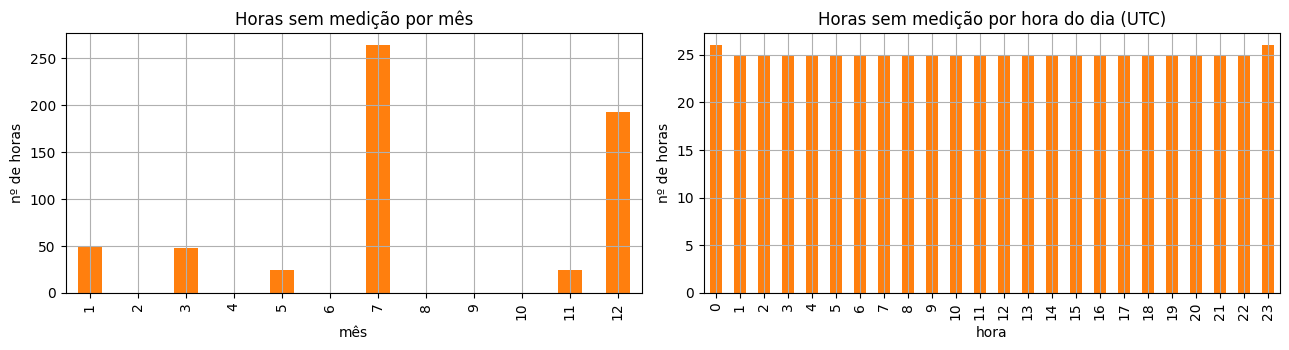

In [92]:
# 2.1.2 Distribuição das falhas por mês e por hora do dia
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
hourly.groupby('month')['missing'].sum().reindex(range(1, 13), fill_value=0).plot.bar(ax=ax[0], color='C1')
ax[0].set(title='Horas sem medição por mês', xlabel='mês', ylabel='nº de horas')
hourly.groupby('hour')['missing'].sum().reindex(range(24), fill_value=0).plot.bar(ax=ax[1], color='C1')
ax[1].set(title='Horas sem medição por hora do dia (UTC)', xlabel='hora', ylabel='nº de horas')
plt.tight_layout()

In [ ]:
# 2.1.3 Verificação de blocos de horas sem medição
full_idx = pd.date_range(hourly.index.min(), hourly.index.max(), freq='h')
print('Horas em falta no índice (timestamps que nem existem):', len(full_idx.difference(hourly.index)))

s = hourly['missing'].reindex(full_idx, fill_value=True)
block_id = (s != s.shift()).cumsum()
gaps = (s[s].groupby(block_id[s])
          .apply(lambda g: pd.Series({'inicio': g.index[0], 'fim': g.index[-1], 'horas': len(g)}))
          .unstack())
gaps['horas'] = gaps['horas'].astype(int)
print('Nº de gaps:', len(gaps))
display(gaps['horas'].describe().to_frame().T.round(1))
display(gaps.sort_values('horas', ascending=False).head(10))

Horas em falta no índice (timestamps que nem existem): 0
Nº de gaps: 5


,count,mean,std,min,25%,50%,75%,max
horas,5.0,120.4,121.7,24.0,24.0,48.0,242.0,264.0


,inicio,fim,horas
missing,,,
6,2025-07-07 23:00:00,2025-07-18 22:00:00,264
10,2025-12-23 23:00:00,2026-01-03 00:00:00,242
2,2025-03-17 23:00:00,2025-03-19 22:00:00,48
4,2025-05-10 23:00:00,2025-05-11 22:00:00,24
8,2025-11-04 23:00:00,2025-11-05 22:00:00,24


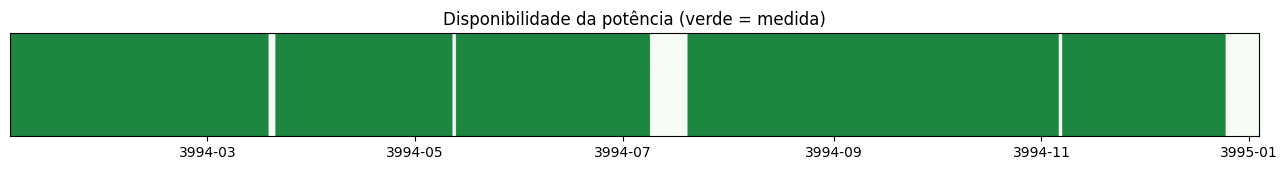

In [ ]:
# 2.1.4 Visão geral da potência (1 = medida, 0 = em falta)
fig, ax = plt.subplots(figsize=(13, 1.8))
ax.imshow((~s).values.astype(int)[None, :], aspect='auto', cmap='Greens', vmin=0, vmax=1.3,
          extent=[full_idx[0].toordinal(), full_idx[-1].toordinal(), 0, 1])
ax.xaxis_date(); ax.set_yticks([]); ax.grid(False); ax.set_title('Disponibilidade da potência (verde = medida)')
plt.tight_layout()

### 2.2 Gamas físicas das variáveis WRF

In [95]:
wrf_cols = [c for c in df.columns if c.split('_')[0] in ('swflx', 'cfl', 'cfm', 'cfh', 'cft', 'temp')
            and not c.endswith('_next')]
rng = df[wrf_cols].agg(['min', 'max', 'mean']).T
rng['NaN'] = df[wrf_cols].isna().sum()
display(rng.round(3))

cf_cols = [c for c in wrf_cols if c.startswith('cf')]
print('cf fora de [0, 1]       :', int(((df[cf_cols] < 0) | (df[cf_cols] > 1)).sum().sum()))
print('swflx < 0               :', int((df[[c for c in wrf_cols if c.startswith('swflx')]] < 0).sum().sum()))
print('swflx máximo (W/m²)     :', df[[c for c in wrf_cols if c.startswith('swflx')]].max().max())

,min,max,mean,NaN
swflx_1,0.000,1001.737,174.718,0
swflx_2,0.000,1002.137,173.974,0
swflx_3,0.000,1007.886,181.305,0
swflx_4,0.000,1006.736,185.375,0
swflx_5,0.000,1013.136,187.318,0
temp,273.491,306.047,287.654,0
cfl_1,0.000,1.000,0.141,0
cfl_2,0.000,1.000,0.139,0
cfl_3,0.000,1.000,0.141,0
cfl_4,0.000,1.000,0.125,0


cf fora de [0, 1]       : 0
swflx < 0               : 0
swflx máximo (W/m²)     : 1013.135925


In [ ]:
# cft deveria ser >= max(cfl, cfm, cfh)
for p in range(1, 6):
    gap_c = df[f'cft_{p}'] - df[[f'cfl_{p}', f'cfm_{p}', f'cfh_{p}']].max(axis=1)
    print(f'ponto {p}: cft < max(cfl,cfm,cfh) em {int((gap_c < -0.01).sum())} linhas '
          f'(mínimo da diferença: {gap_c.min():.3f})')

# Valores "colados" nas variáveis WRF: série horária de swflx_3 (1 valor por hora, lead mais curto)
wrf_h = df.sort_values('lead_time').drop_duplicates('timestamp_utc').set_index('timestamp_utc').sort_index()
day = wrf_h['swflx_3'] > 0
print('\nHoras de dia (swflx_3 > 0) no WRF:', int(day.sum()))

ponto 1: cft < max(cfl,cfm,cfh) em 0 linhas (mínimo da diferença: 0.000)
ponto 2: cft < max(cfl,cfm,cfh) em 0 linhas (mínimo da diferença: 0.000)
ponto 3: cft < max(cfl,cfm,cfh) em 0 linhas (mínimo da diferença: 0.000)
ponto 4: cft < max(cfl,cfm,cfh) em 0 linhas (mínimo da diferença: 0.000)
ponto 5: cft < max(cfl,cfm,cfh) em 0 linhas (mínimo da diferença: 0.000)

Horas de dia (swflx_3 > 0) no WRF: 4228


### 2.3 Análise de valores suspeitos de potência

In [97]:
p = hourly['power'].dropna()
print('Estatísticas da potência (kW, sem NaN):'); display(p.describe().to_frame().T.round(1))
print('Potência < 0           :', int((p < 0).sum()))
print(f'Potência > PMAX ({PMAX}): ', int((p > PMAX).sum()))
print('Potência máxima        :', p.max())
print('Nº de valores exatamente 0:', int((p == 0).sum()), f'({100*(p == 0).mean():.1f} %)')

Estatísticas da potência (kW, sem NaN):


,count,mean,std,min,25%,50%,75%,max
power,8206.0,2592.9,3940.0,0.0,0.0,23.7,4312.6,13530.7


Potência < 0           : 0
Potência > PMAX (13531):  0
Potência máxima        : 13530.74504
Nº de valores exatamente 0: 3848 (46.9 %)


In [ ]:
# 2.3.1 Potência não nula de noite. Noite segundo o WRF: swflx_3 == 0 em t e em t+1h
night_flag = (df['swflx_3'] == 0) & (df['swflx_3_next'] == 0)
night_rows = df[night_flag & df['power'].notna()]
print('Linhas de noite (WRF) com power medido     :', len(night_rows))
print('  das quais com power > 0                  :', int((night_rows['power'] > 0).sum()))
print('  das quais com power > 100 kW             :', int((night_rows['power'] > 100).sum()))
display(night_rows.loc[night_rows['power'] > 0, 'power'].describe().to_frame().T.round(1))

# Noite segundo as próprias horas do dia: potência observada por hora do dia (UTC)
prof = hourly.groupby('hour')['power'].agg(['mean', 'max'])
display(prof.T.round(0))

Linhas de noite (WRF) com power medido     : 11337
  das quais com power > 0                  : 368
  das quais com power > 100 kW             : 24


,count,mean,std,min,25%,50%,75%,max
power,368.0,21.9,59.7,0.0,0.2,0.8,9.0,417.6


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
mean,0.0,0.0,0.0,0.0,0.0,11.0,175.0,944.0,2948.0,5167.0,7103.0,8290.0,8825.0,8799.0,7834.0,6076.0,3868.0,1754.0,375.0,46.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0,194.0,1166.0,2733.0,6686.0,9799.0,11947.0,13171.0,13531.0,13355.0,12539.0,10564.0,7928.0,5423.0,2446.0,830.0,4.0,0.0,0.0,0.0


In [ ]:
# 2.3.2 Potência ~0 em pleno dia com irradiância alta --> possível avaria, sombra ou limitação de produção
D = df[df['power'].notna() & df['swflx_3_next'].notna()].copy()
D['swflx_avg_3'] = (D['swflx_3'] + D['swflx_3_next']) / 2
LIM_SW, LIM_P = 400, 50                         # limiares exploratórios (W/m² e kW): ajusta
sus = D[(D['swflx_avg_3'] > LIM_SW) & (D['power'] < LIM_P)]
print(f'Linhas com swflx_avg_3 > {LIM_SW} W/m² e power < {LIM_P} kW:', len(sus),
      f'({sus.groupby("timestamp_utc").ngroups} horas distintas)')
display(sus.groupby(sus['timestamp_utc'].dt.date).size().sort_values(ascending=False).head(10).to_frame('nº de linhas'))

Linhas com swflx_avg_3 > 400 W/m² e power < 50 kW: 21 (7 horas distintas)


,nº de linhas
timestamp_utc,
2025-05-12,21


In [ ]:
# 2.3.3 Valores de horas consecutivas com exatamente o mesmo power > 0
ps = hourly['power'].reindex(full_idx)
same = (ps == ps.shift()) & (ps > 0)
run_id = (~same).cumsum()
runs = same.groupby(run_id).sum()               # nº de repetições em cada bloco
print('Blocos com o mesmo valor > 0 repetido >= 2 vezes:', int((runs >= 2).sum()))
print('Maior bloco (nº de repetições):', int(runs.max()))
if (runs >= 2).any():
    k = runs[runs >= 2].sort_values(ascending=False).head(5).index
    for kk in k:
        idx = same[run_id == kk].index
        print(f'  {idx.min()} -> {idx.max()}  valor = {ps[idx.min()]:.1f}  ({int(runs[kk])} repetições)')

Blocos com o mesmo valor > 0 repetido >= 2 vezes: 0
Maior bloco (nº de repetições): 0


### 2.4 Unidades e convenção temporal

In [ ]:
# 2.4.1 Confirmação da ordem de grandeza
print('Potência máxima observada :', p.max())
print('Potência média (horas c/ sol, power>0):', round(p[p > 0].mean(), 1))
print('Rácio power máx / 15 (kWp)           :', round(p.max() / 15, 1))
print('Ex.: enunciado dá 6815.3 como exemplo de forecast; o checker avisa acima de 20 000.')

Potência máxima observada : 13530.74504
Potência média (horas c/ sol, power>0): 4882.3
Rácio power máx / 15 (kWp)           : 902.0
Ex.: enunciado dá 6815.3 como exemplo de forecast; o checker avisa acima de 20 000.


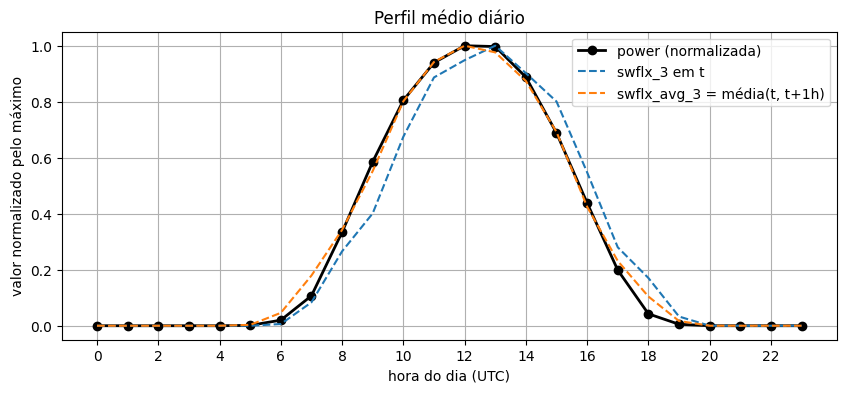

Hora do máximo -> power: 12 | swflx_3: 13 | swflx_avg_3: 12


In [ ]:
# 2.4.2 Convenção temporal --> power em [t, t+1h[ vs WRF instantâneo em t e em t+1h
H = df.sort_values('lead_time').drop_duplicates('timestamp_utc').set_index('timestamp_utc').sort_index()
H['swflx_3_next'] = H['swflx_3'].shift(-1)                    # série horária contínua do WRF
H['swflx_avg_3']  = (H['swflx_3'] + H['swflx_3_next']) / 2
H['hour'] = H.index.hour
cmp = H.groupby('hour')[['swflx_3', 'swflx_avg_3']].mean()
cmp['power'] = hourly.groupby('hour')['power'].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cmp.index, cmp['power'] / cmp['power'].max(), 'k-o', lw=2, label='power (normalizada)')
ax.plot(cmp.index, cmp['swflx_3'] / cmp['swflx_3'].max(), '--', label='swflx_3 em t')
ax.plot(cmp.index, cmp['swflx_avg_3'] / cmp['swflx_avg_3'].max(), '--', label='swflx_avg_3 = média(t, t+1h)')
ax.set(xlabel='hora do dia (UTC)', ylabel='valor normalizado pelo máximo', title='Perfil médio diário', xticks=range(0, 24, 2))
ax.legend()
plt.show()
print('Hora do máximo -> power:', cmp['power'].idxmax(), '| swflx_3:', cmp['swflx_3'].idxmax(),
      '| swflx_avg_3:', cmp['swflx_avg_3'].idxmax())

### 2.5 Outliers

Linhas com |resíduo| > 4 desvios-padrão: 211 de 24207


,timerequests,timestamp_utc,lead_time,power,swflx_3,swflx_avg_3,cft_3
274,2025-01-04,2025-01-06 11:00:00,59,8482.18816,117.900002,95.000000,0.457924
275,2025-01-04,2025-01-06 12:00:00,60,9924.12847,72.099998,56.750000,0.400000
276,2025-01-04,2025-01-06 13:00:00,61,9457.94097,41.400002,26.400001,0.500000
1308,2025-01-19,2025-01-19 13:00:00,13,10767.36690,391.341736,285.119614,0.200000
2075,2025-01-29,2025-01-31 12:00:00,60,9216.99653,126.729103,72.544442,0.820000
2171,2025-01-31,2025-01-31 12:00:00,12,9216.99653,244.464645,143.076521,0.000000
2797,2025-02-08,2025-02-10 14:00:00,62,10044.76852,282.867065,207.119949,0.100000
2890,2025-02-10,2025-02-10 11:00:00,11,10701.35995,265.189026,290.013077,0.371265
3657,2025-02-20,2025-02-22 10:00:00,58,8108.48429,23.799999,30.415133,0.843750
3753,2025-02-22,2025-02-22 10:00:00,10,8108.48429,36.000000,49.558353,0.640625


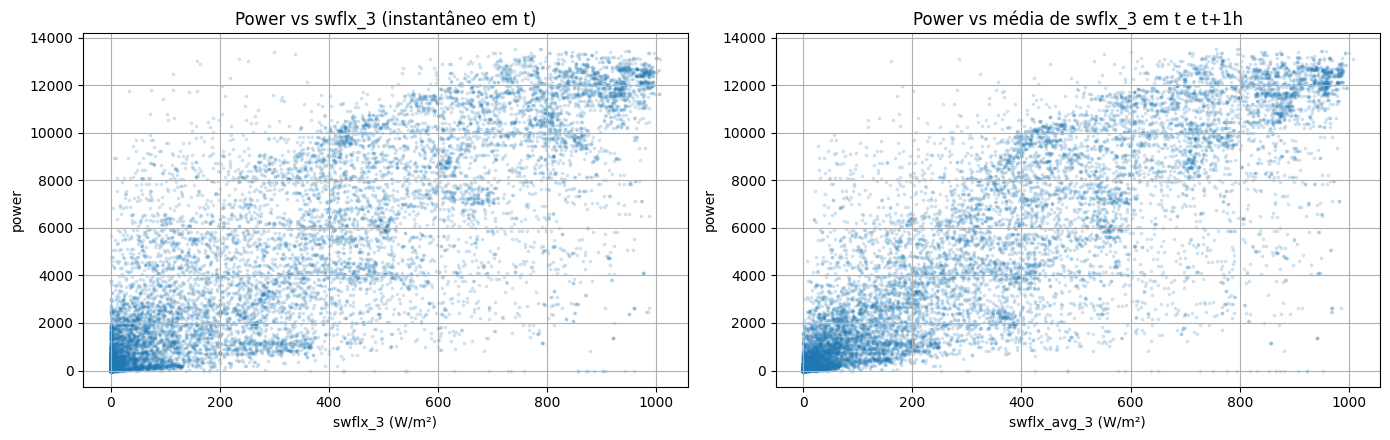

In [103]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(D['swflx_3'], D['power'], s=3, alpha=0.15)
ax[0].set(xlabel='swflx_3 (W/m²)', ylabel='power', title='Power vs swflx_3 (instantâneo em t)')
ax[1].scatter(D['swflx_avg_3'], D['power'], s=3, alpha=0.15)
ax[1].set(xlabel='swflx_avg_3 (W/m²)', ylabel='power', title='Power vs média de swflx_3 em t e t+1h')
plt.tight_layout()

# Resíduos de uma regressão simples power ~ swflx_avg_3 (só para marcar candidatos a outlier)
lr = np.polyfit(D['swflx_avg_3'], D['power'], 1)
D['resid'] = D['power'] - np.polyval(lr, D['swflx_avg_3'])
z = (D['resid'] - D['resid'].mean()) / D['resid'].std()
print('Linhas com |resíduo| > 4 desvios-padrão:', int((z.abs() > 4).sum()), 'de', len(D))
display(D.loc[z.abs() > 4, ['timerequests', 'timestamp_utc', 'lead_time', 'power', 'swflx_3', 'swflx_avg_3', 'cft_3']].head(10))

### 2.6 Tabela-resumo do problema

In [131]:
n = lambda x: int(x)
summary = pd.DataFrame([
    ['Potência em falta (-99999)',                         n(df['power_missing'].sum())],
    ['  horas distintas sem medição',                      n(hourly['missing'].sum())],
    ['  nº de gaps (blocos contíguos)',                    len(gaps)],
    ['NaN nas variáveis WRF (treino)',                     n(df[wrf_cols].isna().sum().sum())],
    ['cf fora de [0, 1]',                                  n(((df[cf_cols] < 0) | (df[cf_cols] > 1)).sum().sum())],
    ['swflx < 0',                                          n((df[[c for c in wrf_cols if c.startswith('swflx')]] < 0).sum().sum())],
    ['Potência < 0',                                       n((df['power'] < 0).sum())],
    [f'Potência > PMAX ({PMAX})',                          n((df['power'] > PMAX).sum())],
    ['Power > 0 de noite (swflx_3 = 0 em t e t+1h)',       n((night_rows['power'] > 0).sum())],
    [f'Power < {LIM_P} com swflx_avg_3 > {LIM_SW} (dia)',  len(sus)],
    ['Blocos de valor repetido > 0 (>= 2 repetições)',     n((runs >= 2).sum())],
    ['Resíduo > 4 desvios-padrão (candidatos a outlier)',  n((z.abs() > 4).sum())],
], columns=['Problema', 'Linhas afetadas'])
summary

,Problema,Linhas afetadas
0,Potência em falta (-99999),1734
1,horas distintas sem medição,602
2,nº de gaps (blocos contíguos),5
3,NaN nas variáveis WRF (treino),0
4,"cf fora de [0, 1]",0
5,swflx < 0,0
6,Potência < 0,0
7,Potência > PMAX (13531),0
8,Power > 0 de noite (swflx_3 = 0 em t e t+1h),368
9,Power < 50 com swflx_avg_3 > 400 (dia),21


---
## 3. Análise exploratória (EDA)

In [ ]:
# 3.0 Linhas com potência medida e swflx em t+1h (mesmo run); features simples
for p in range(1, 6):                          # swflx em t+1h (mesmo run), calculado ANTES de filtrar linhas
    df[f'swflx_{p}_next'] = df.groupby('timerequests')[f'swflx_{p}'].shift(-1)
    df[f'swflx_avg_{p}']  = (df[f'swflx_{p}'] + df[f'swflx_{p}_next']) / 2
D = df[df['power'].notna() & df['swflx_3_next'].notna()].copy()
D['hour']  = D['timestamp_utc'].dt.hour
D['month'] = D['timestamp_utc'].dt.month
D['doy']   = D['timestamp_utc'].dt.dayofyear
D['cft_avg_3']   = (D['cft_3'] + D['cft_3_next']) / 2
D24 = D[D['lead_time'] <= MAX_LEAD].copy()
print('Linhas (todos os leads):', len(D), '| leads 1-24:', len(D24))

Linhas (todos os leads): 24207 | leads 1-24: 8206


### 3.1 Potência por hora do dia e por mês

Potência média mensal (kW):


month,1,2,3,4,5,6,7,8,9,10,11,12
média,1605.0,1884.0,2871.0,2959.0,3361.0,3474.0,3545.0,3174.0,3064.0,1980.0,1951.0,1212.0


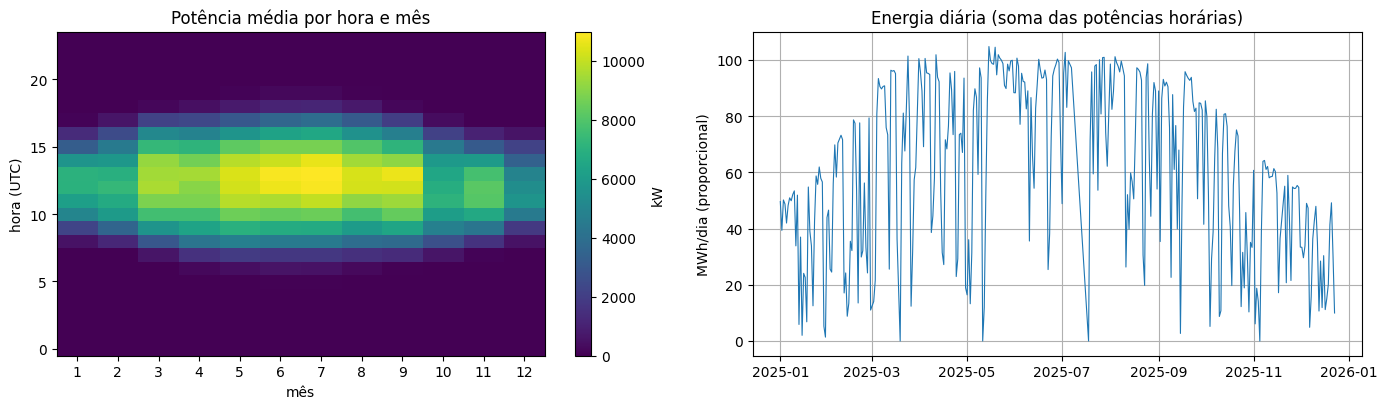

In [106]:
H24 = hourly.dropna(subset=['power'])           # uma linha por hora medida
heat = H24.pivot_table(index='hour', columns='month', values='power', aggfunc='mean')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].imshow(heat.values, aspect='auto', origin='lower', cmap='viridis',
                  extent=[0.5, 12.5, -0.5, 23.5])
ax[0].set(xlabel='mês', ylabel='hora (UTC)', title='Potência média por hora e mês', xticks=range(1, 13))
ax[0].grid(False); fig.colorbar(im, ax=ax[0], label='kW')

daily = H24['power'].groupby(H24.index.normalize()).sum()
ax[1].plot(daily.index, daily.values / 1e3, lw=0.8)
ax[1].set(title='Energia diária (soma das potências horárias)', ylabel='MWh/dia (proporcional)')
plt.tight_layout()

print('Potência média mensal (kW):')
display(H24.groupby('month')['power'].mean().round(0).to_frame('média').T)

### 3.2 Relação com as variáveis WRF

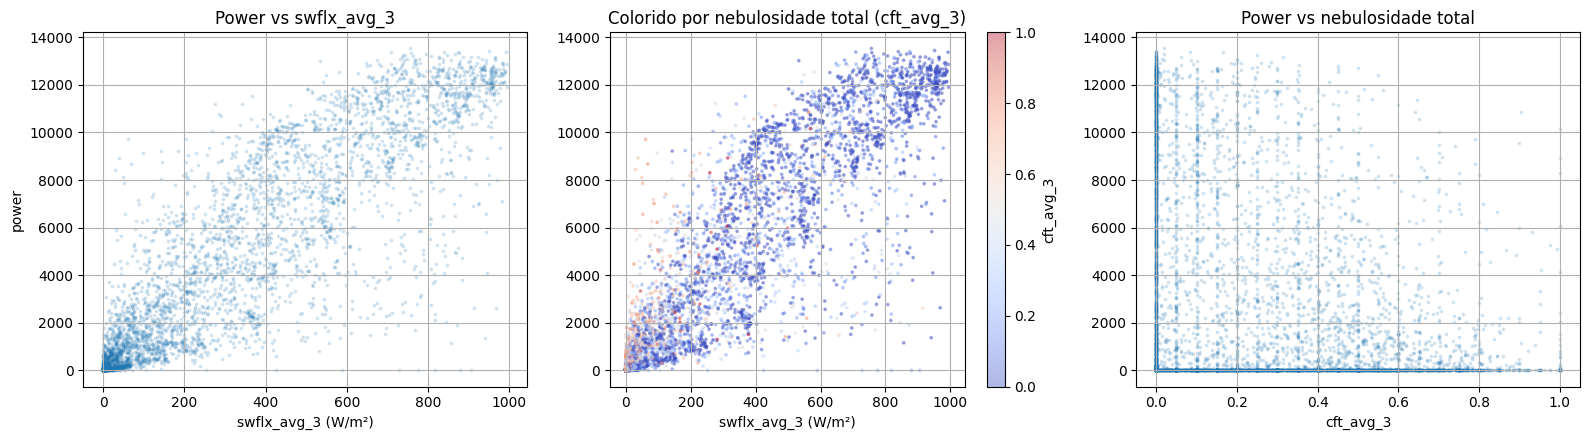

In [107]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(D24['swflx_avg_3'], D24['power'], s=3, alpha=0.15)
ax[0].set(xlabel='swflx_avg_3 (W/m²)', ylabel='power', title='Power vs swflx_avg_3')
sc = ax[1].scatter(D24['swflx_avg_3'], D24['power'], c=D24['cft_avg_3'], s=3, alpha=0.4, cmap='coolwarm')
ax[1].set(xlabel='swflx_avg_3 (W/m²)', title='Colorido por nebulosidade total (cft_avg_3)')
fig.colorbar(sc, ax=ax[1], label='cft_avg_3')
ax[2].scatter(D24['cft_avg_3'], D24['power'], s=3, alpha=0.15)
ax[2].set(xlabel='cft_avg_3', title='Power vs nebulosidade total')
plt.tight_layout()

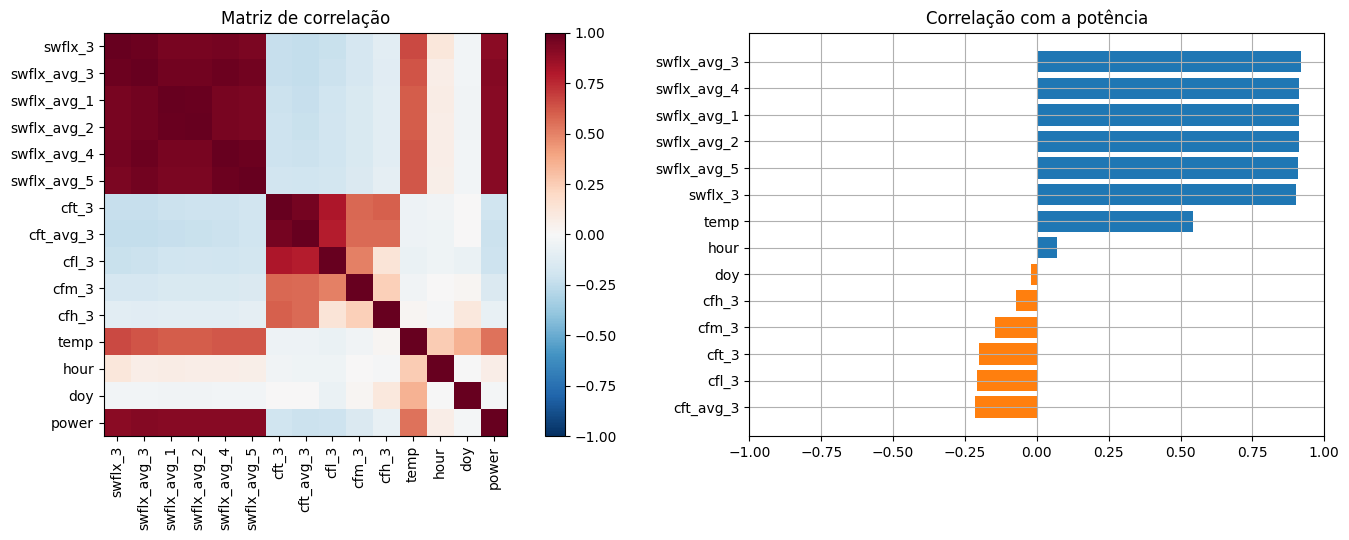

In [ ]:
# Matriz de correlação entre power e as variáveis candidatas, leads 1-24
cand = ['swflx_3', 'swflx_avg_3', 'swflx_avg_1', 'swflx_avg_2', 'swflx_avg_4', 'swflx_avg_5',
        'cft_3', 'cft_avg_3', 'cfl_3', 'cfm_3', 'cfh_3', 'temp', 'hour', 'doy']
corr = D24[cand + ['power']].corr()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
im = ax[0].imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax[0].set_xticks(range(len(corr))); ax[0].set_xticklabels(corr.columns, rotation=90)
ax[0].set_yticks(range(len(corr))); ax[0].set_yticklabels(corr.columns); ax[0].grid(False)
ax[0].set_title('Matriz de correlação'); fig.colorbar(im, ax=ax[0])
c = corr['power'].drop('power').sort_values()
ax[1].barh(c.index, c.values, color=['C0' if v > 0 else 'C1' for v in c])
ax[1].set(title='Correlação com a potência', xlim=(-1, 1))
plt.tight_layout()

In [109]:
# Correlação entre os 5 pontos da grelha (swflx_avg) e entre nebulosidades
print('Correlação entre pontos da grelha (swflx_avg):')
display(D24[[f'swflx_avg_{p}' for p in range(1, 6)]].corr().round(3))
print('Desvio-padrão entre os 5 pontos (média, W/m²):',
      round(D24[[f'swflx_{p}' for p in range(1, 6)]].std(axis=1).mean(), 1))

Correlação entre pontos da grelha (swflx_avg):


,swflx_avg_1,swflx_avg_2,swflx_avg_3,swflx_avg_4,swflx_avg_5
swflx_avg_1,1.000,0.990,0.968,0.950,0.942
swflx_avg_2,0.990,1.000,0.965,0.950,0.942
swflx_avg_3,0.968,0.965,1.000,0.979,0.965
swflx_avg_4,0.950,0.950,0.979,1.000,0.979
swflx_avg_5,0.942,0.942,0.965,0.979,1.000


Desvio-padrão entre os 5 pontos (média, W/m²): 25.3


### 3.3 Como muda a previsão com o lead time

,linhas,"corr(power, swflx_avg_3)",RMSE ajuste linear (kW)
leads,,,
1-24,8206,0.918,2128.263
25-48,8182,0.909,2229.263
49-72,7819,0.900,2300.908


Correlação entre as 3 previsões da mesma hora e a potência:


,lead h,lead h+24,lead h+48,power
lead h,1.000,0.948,0.935,0.901
lead h+24,0.948,1.000,0.946,0.890
lead h+48,0.935,0.946,1.000,0.882
power,0.901,0.890,0.882,1.000


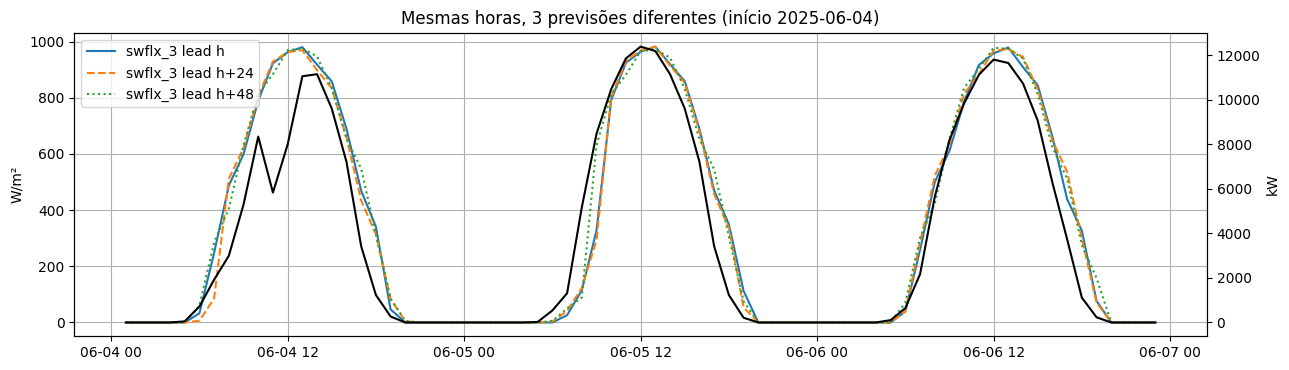

In [110]:
D['lead_group'] = pd.cut(D['lead_time'], [0, 24, 48, 72], labels=['1-24', '25-48', '49-72'])
rows = []
for g, d in D.groupby('lead_group', observed=True):
    day = d[d['swflx_avg_3'] > 0]
    coef = np.polyfit(day['swflx_avg_3'], day['power'], 1)
    rows.append({'leads': g, 'linhas': len(d),
                 'corr(power, swflx_avg_3)': d[['power', 'swflx_avg_3']].corr().iloc[0, 1],
                 'RMSE ajuste linear (kW)': np.sqrt(np.mean((day['power'] - np.polyval(coef, day['swflx_avg_3'])) ** 2))})
display(pd.DataFrame(rows).set_index('leads').round(3))

# Mesma hora prevista por 3 runs: swflx_3 em lead h, h+24 e h+48 (um período de 3 dias em junho)
P = D[D['lead_time'] <= 24].set_index('timestamp_utc')['swflx_3'].rename('lead h')
P24 = D[(D['lead_time'] > 24) & (D['lead_time'] <= 48)].set_index('timestamp_utc')['swflx_3'].rename('lead h+24')
P48 = D[D['lead_time'] > 48].set_index('timestamp_utc')['swflx_3'].rename('lead h+48')
three = pd.concat([P, P24, P48, hourly['power']], axis=1).dropna()
print('Correlação entre as 3 previsões da mesma hora e a potência:')
display(three.corr().round(3))

day0 = three.index[three.index.month == 6][0].normalize() + pd.Timedelta(days=3)
w = three.loc[day0: day0 + pd.Timedelta(days=3)]
fig, ax = plt.subplots(figsize=(13, 3.8))
for c, st in zip(['lead h', 'lead h+24', 'lead h+48'], ['-', '--', ':']):
    ax.plot(w.index, w[c], st, label=f'swflx_3 {c}')
ax2 = ax.twinx(); ax2.plot(w.index, w['power'], 'k', lw=1.5, label='power'); ax2.grid(False)
ax.set(title=f'Mesmas horas, 3 previsões diferentes (início {day0.date()})', ylabel='W/m²'); ax2.set_ylabel('kW')
ax.legend(loc='upper left')
plt.tight_layout()

### 3.4 Comparação dos dados de teste e treino?

,treino jan-jun,teste jan-jun,diferença %
swflx_avg_3,197.204,176.444,-10.527
cft_avg_3,0.209,0.286,36.522
temp,285.890,285.531,-0.125


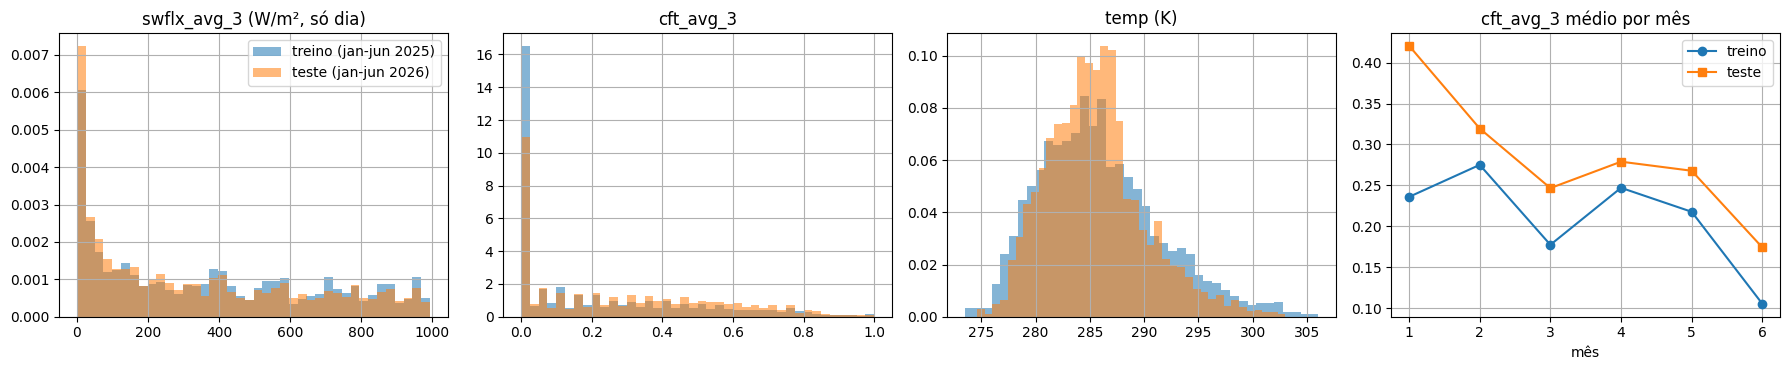

In [111]:
test_df = test.sort_values(['timerequests', 'lead_time']).reset_index(drop=True)
test_df['swflx_3_next'] = test_df.groupby('timerequests')['swflx_3'].shift(-1)
test_df['cft_3_next']   = test_df.groupby('timerequests')['cft_3'].shift(-1)
test_df['swflx_avg_3']  = (test_df['swflx_3'] + test_df['swflx_3_next']) / 2
test_df['cft_avg_3']    = (test_df['cft_3'] + test_df['cft_3_next']) / 2
test_df['month'] = test_df['timestamp_utc'].dt.month

tr_cmp = D24[D24['month'] <= 6]
te_cmp = test_df[(test_df['lead_time'] <= MAX_LEAD) & (test_df['month'] <= 6)].dropna(subset=['swflx_avg_3'])

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, (v, lab) in zip(ax[:3], [('swflx_avg_3', 'swflx_avg_3 (W/m², só dia)'), ('cft_avg_3', 'cft_avg_3'),
                                ('temp', 'temp (K)')]):
    x1, x2 = tr_cmp[v], te_cmp[v]
    if v == 'swflx_avg_3':
        x1, x2 = x1[x1 > 0], x2[x2 > 0]
    a.hist(x1, bins=40, alpha=0.55, density=True, label='treino (jan-jun 2025)')
    a.hist(x2, bins=40, alpha=0.55, density=True, label='teste (jan-jun 2026)')
    a.set(title=lab);
ax[0].legend()
# 4.º gráfico: nebulosidade total média por mês
m1 = tr_cmp.groupby('month')['cft_avg_3'].mean(); m2 = te_cmp.groupby('month')['cft_avg_3'].mean()
ax[3].plot(m1.index, m1.values, 'o-', label='treino'); ax[3].plot(m2.index, m2.values, 's-', label='teste')
ax[3].set(title='cft_avg_3 médio por mês', xlabel='mês'); ax[3].legend()
plt.tight_layout()

cmp_tbl = pd.DataFrame({'treino jan-jun': tr_cmp[['swflx_avg_3', 'cft_avg_3', 'temp']].mean(),
                        'teste jan-jun':  te_cmp[['swflx_avg_3', 'cft_avg_3', 'temp']].mean()})
cmp_tbl['diferença %'] = 100 * (cmp_tbl['teste jan-jun'] / cmp_tbl['treino jan-jun'] - 1)
display(cmp_tbl.round(3))

In [ ]:
# Diferença de distribuição treino vs teste para os mesmos meses
from scipy.stats import ks_2samp
for v in ['swflx_avg_3', 'cft_avg_3', 'cfl_3', 'cfm_3', 'cfh_3', 'temp']:
    a_, b_ = tr_cmp[v].dropna(), te_cmp[v].dropna()
    if v == 'swflx_avg_3':
        a_, b_ = a_[a_ > 0], b_[b_ > 0]
    s_, p_ = ks_2samp(a_, b_)
    print(f'{v:12s} KS = {s_:.3f}  p = {p_:.3g}')

swflx_avg_3  KS = 0.070  p = 2.76e-05
cft_avg_3    KS = 0.154  p = 4.74e-45
cfl_3        KS = 0.149  p = 6.06e-42
cfm_3        KS = 0.089  p = 2.82e-15
cfh_3        KS = 0.107  p = 5.58e-22
temp         KS = 0.078  p = 6.61e-12


---
## 4. Construção das amostras de treino e de teste

In [ ]:
# 4.1 Configuração das amostras
TRAIN_LEADS  = 24            # 24 = só leads 1-24 no treino | 72 = todos os leads (usa então 'lead_time' como feature)
POINTS       = [1, 2, 3, 4, 5]
EXCLUDE_ROWS = None

# NWP de todos os runs (treino + teste), sem a potência
nwp_all = pd.concat([train.drop(columns='power'), test], ignore_index=True)
nwp_all = nwp_all.sort_values(['timerequests', 'lead_time']).reset_index(drop=True)
print('NWP total:', nwp_all.shape, '| runs:', nwp_all['timerequests'].nunique())

NWP total: (39168, 29) | runs: 544


In [114]:
# 4.2 Função que constrói TODAS as features candidatas a partir do NWP (sem usar potência)
def build_features(nwp):
    f = nwp.sort_values(['timerequests', 'lead_time']).reset_index(drop=True).copy()
    g = f.groupby('timerequests')

    # --- valores em t+1h do MESMO run (lead L+1) e médias de [t, t+1h] ---
    for p in POINTS:
        f[f'swflx_{p}_next'] = g[f'swflx_{p}'].shift(-1)
        f[f'cft_{p}_next']   = g[f'cft_{p}'].shift(-1)
        f[f'swflx_avg_{p}']  = (f[f'swflx_{p}'] + f[f'swflx_{p}_next']) / 2
        f[f'cft_avg_{p}']    = (f[f'cft_{p}'] + f[f'cft_{p}_next']) / 2

    # --- informação espacial (5 pontos da grelha) ---
    sw = f[[f'swflx_avg_{p}' for p in POINTS]]; cf = f[[f'cft_avg_{p}' for p in POINTS]]
    f['swflx_avg_mean'], f['swflx_avg_std'] = sw.mean(axis=1), sw.std(axis=1)
    f['swflx_avg_min'],  f['swflx_avg_max'] = sw.min(axis=1),  sw.max(axis=1)
    f['cft_avg_mean'],   f['cft_avg_std']   = cf.mean(axis=1), cf.std(axis=1)

    # --- calendário (hora e dia do ano de t) ---
    f['hour']  = f['timestamp_utc'].dt.hour
    f['month'] = f['timestamp_utc'].dt.month
    f['doy']   = f['timestamp_utc'].dt.dayofyear
    f['hour_sin'], f['hour_cos'] = np.sin(2 * np.pi * f['hour'] / 24), np.cos(2 * np.pi * f['hour'] / 24)
    f['doy_sin'],  f['doy_cos']  = np.sin(2 * np.pi * f['doy'] / 365.25), np.cos(2 * np.pi * f['doy'] / 365.25)
    for h in range(24):
        f[f'hour_{h}'] = (f['hour'] == h).astype(int)            # one-hot da hora (UTC)

    # --- runs anteriores: mesma hora prevista pelos runs k-1 (lead L+24) e k-2 (lead L+48) ---
    look = f[['timerequests', 'timestamp_utc', 'swflx_3', 'cft_3']]
    for days, tag in [(1, 'prev24'), (2, 'prev48')]:
        key = f[['timerequests', 'timestamp_utc']].copy()
        key['timerequests'] = key['timerequests'] - pd.Timedelta(days=days)
        old = key.merge(look, on=['timerequests', 'timestamp_utc'], how='left')
        f[f'swflx_3_{tag}'] = old['swflx_3'].values
        f[f'cft_3_{tag}']   = old['cft_3'].values
    # sem run anterior (só os 2 primeiros runs do treino): usa o valor do próprio run
    f['no_prev_run'] = f['swflx_3_prev48'].isna().astype(int)
    for tag in ('prev24', 'prev48'):
        f[f'swflx_3_{tag}'] = f[f'swflx_3_{tag}'].fillna(f['swflx_3'])
        f[f'cft_3_{tag}']   = f[f'cft_3_{tag}'].fillna(f['cft_3'])

    # --- variáveis derivadas (candidatas a FS5) ---
    f['swflx_trend']    = f['swflx_3_next'] - f['swflx_3']                    # variação dentro da hora
    f['swflx_x_clear']  = f['swflx_avg_3'] * (1 - f['cft_avg_3'])             # irradiância x céu limpo
    f['swflx_d24']      = f['swflx_3'] - f['swflx_3_prev24']                  # mudança face ao run anterior
    f['swflx_runs_std'] = f[['swflx_3', 'swflx_3_prev24', 'swflx_3_prev48']].std(axis=1)
    f['night']          = ((f['swflx_3'] == 0) & (f['swflx_3_next'] == 0)).astype(int)
    return f

feat = build_features(nwp_all)
print('Features construídas:', feat.shape)
print('Linhas de leads 1-24 sem run anterior (preenchidas com o valor do próprio run):',
      int(feat.loc[feat['lead_time'] <= MAX_LEAD, 'no_prev_run'].sum()), '(= 2 primeiros runs do treino)')
print('Nota: para leads > 24 (prev48) e > 48 (prev24) o run anterior não cobre a hora; essas linhas só importam se TRAIN_LEADS = 72.')

Features construídas: (39168, 96)
Linhas de leads 1-24 sem run anterior (preenchidas com o valor do próprio run): 48 (= 2 primeiros runs do treino)
Nota: para leads > 24 (prev48) e > 48 (prev24) o run anterior não cobre a hora; essas linhas só importam se TRAIN_LEADS = 72.


In [ ]:
# 4.3 Juntar a potência (só treino), separar treino/teste
power_df = df[['timerequests', 'lead_time', 'power']]                  # potência já com NaN em vez de -99999
feat = feat.merge(power_df, on=['timerequests', 'lead_time'], how='left')

last_train_run = train['timerequests'].max()
is_train = feat['timerequests'] <= last_train_run
is_test  = ~is_train

data_all = feat[is_train & feat['power'].notna()].copy()               # treino com potência medida (leads 1-72)
if EXCLUDE_ROWS is not None:
    data_all = data_all[~EXCLUDE_ROWS.reindex(data_all.index, fill_value=False)]
data_all['run_month'] = data_all['timerequests'].dt.month
data24 = data_all[data_all['lead_time'] <= MAX_LEAD]                   # linhas de validação (e treino se TRAIN_LEADS=24)
y_val = data24['power']

test_X = template[['timerequests', 'timestamp_utc', 'lead_time']].merge(
    feat[is_test], on=['timerequests', 'timestamp_utc', 'lead_time'], how='left')

print(f'data_all (leads 1-72, power medida): {len(data_all):,} | data24 (leads 1-24): {len(data24):,}')
print(f'test_X: {test_X.shape}  (template: {template.shape})')
assert len(test_X) == len(template) == 4296
assert test_X['swflx_3'].notna().all(), 'há linhas do template sem NWP'

data_all (leads 1-72, power medida): 24,546 | data24 (leads 1-24): 8,206
test_X: (4296, 97)  (template: (4296, 4))


### 4.4 Verificações anti-fuga de informação

In [ ]:
# Nenhuma feature de um run pode depender de runs posteriores
feat_cols = [c for c in feat.columns if c not in ('timerequests', 'timestamp_utc', 'power')]
rng = np.random.default_rng(SEED)
runs_all = np.sort(nwp_all['timerequests'].unique())
for k in rng.choice(runs_all[3:], size=3, replace=False):
    sub = build_features(nwp_all[nwp_all['timerequests'] <= k])
    a = feat[feat['timerequests'] == k].reset_index(drop=True)[feat_cols]
    b = sub[sub['timerequests'] == k].reset_index(drop=True)[feat_cols]
    assert np.allclose(a.values.astype(float), b.values.astype(float), equal_nan=True)
    print('run', pd.Timestamp(k).date(), ': features idênticas sem os runs posteriores  OK')

# swflx_3_prev24 / prev48 correspondem a leads L+24 / L+48 do mesmo timestamp
row = data24.iloc[1000]
t0 = row['timestamp_utc']
for days, tag in [(1, 'prev24'), (2, 'prev48')]:
    ref = nwp_all[(nwp_all['timerequests'] == row['timerequests'] - pd.Timedelta(days=days)) & (nwp_all['timestamp_utc'] == t0)]
    print(f'{tag}: linha={row[f"swflx_3_{tag}"]:.2f}  | run k-{days}, lead {int(ref["lead_time"].iloc[0])}: {ref["swflx_3"].iloc[0]:.2f}')

# O teste não usa potência e as features do teste não têm NaN
print('\nNaN nas features do teste (total):', int(test_X[feat_cols].isna().sum().sum()),
      '(esperados só em *_next do lead 72, que não está no template)')

run 2025-12-24 : features idênticas sem os runs posteriores  OK
run 2025-02-21 : features idênticas sem os runs posteriores  OK
run 2026-02-25 : features idênticas sem os runs posteriores  OK
prev24: linha=46.42  | run k-1, lead 41: 46.42
prev48: linha=23.66  | run k-2, lead 65: 23.66

NaN nas features do teste (total): 0 (esperados só em *_next do lead 72, que não está no template)


### 4.5 Resumo das amostras

In [117]:
print('Linhas de treino por lead (primeiras / últimas):')
cnt = data_all.groupby('lead_time').size()
display(cnt.iloc[[0, 1, 11, 23, 24, 47, 71]].to_frame('linhas').T)
print(f'TRAIN_LEADS = {TRAIN_LEADS} -> linhas usadas para ajustar modelos: ',
      int((data_all['lead_time'] <= TRAIN_LEADS).sum()))
print('Linhas de validação (leads 1-24, power medida):', len(data24))

Linhas de treino por lead (primeiras / últimas):


lead_time,1,2,12,24,25,48,72
linhas,342,342,342,341,341,340,339


TRAIN_LEADS = 24 -> linhas usadas para ajustar modelos:  8206
Linhas de validação (leads 1-24, power medida): 8206


---
## 5. Engenharia de variáveis e feature sets

### 5.1 Definição dos feature sets

In [118]:
HOUR_OH = [f'hour_{h}' for h in range(24)]
pts_sw  = [f'swflx_{p}' for p in POINTS] + [f'swflx_{p}_next' for p in POINTS]
pts_cf  = [f'cft_{p}' for p in POINTS]

def uniq(seq):                                   # remove repetidos mantendo a ordem
    return list(dict.fromkeys(seq))

FEATURE_SETS = {}
FEATURE_SETS['FS1'] = ['swflx_3']
FEATURE_SETS['FS2'] = ['swflx_3', 'swflx_3_next', 'cft_3'] + HOUR_OH
FEATURE_SETS['FS3'] = uniq(FEATURE_SETS['FS2'] + pts_sw + pts_cf + ['cfl_3', 'cfm_3', 'cfh_3', 'temp', 'doy_sin', 'doy_cos'])
FEATURE_SETS['FS4'] = uniq(FEATURE_SETS['FS3'] + ['swflx_avg_mean', 'swflx_avg_std', 'cft_avg_mean', 'cft_avg_std',
                                                   'swflx_3_prev24', 'swflx_3_prev48'])
FEATURE_SETS['FS5'] = uniq(FEATURE_SETS['FS4'] + ['swflx_trend', 'swflx_x_clear', 'swflx_d24', 'swflx_runs_std', 'night'])
# se TRAIN_LEADS = 72, junta 'lead_time' aos conjuntos que usares

assert all(c in feat.columns for fs in FEATURE_SETS.values() for c in fs), 'feature em falta em feat'
desc = {'FS1': 'swflx_3',
        'FS2': 'swflx_3 em t e t+1h, cft_3, hora (one-hot)',
        'FS3': 'FS2 + swflx/cft dos 5 pontos, cfl/cfm/cfh_3, temp, sin/cos do dia do ano',
        'FS4': 'FS3 + média/desvio espacial de swflx e cft, swflx_3 dos runs 24 h e 48 h antes',
        'FS5': 'FS4 + variáveis derivadas (tendência, swflx x céu limpo, mudança entre runs, indicador de noite)'}
pd.DataFrame({'Set': list(FEATURE_SETS), 'Nº features': [len(v) for v in FEATURE_SETS.values()],
              'Conteúdo': [desc.get(k, '') for k in FEATURE_SETS]}).set_index('Set')

,Nº features,Conteúdo
Set,,
FS1,1,swflx_3
FS2,27,"swflx_3 em t e t+1h, cft_3, hora (one-hot)"
FS3,45,"FS2 + swflx/cft dos 5 pontos, cfl/cfm/cfh_3, t..."
FS4,51,"FS3 + média/desvio espacial de swflx e cft, sw..."
FS5,56,"FS4 + variáveis derivadas (tendência, swflx x ..."


### 5.3 Verificação dos conjuntos

In [ ]:
# NaN em treino e em teste
chk = pd.DataFrame({k: {'NaN treino (data24)': int(data24[v].isna().sum().sum()),
                        'NaN treino (data_all)': int(data_all[v].isna().sum().sum()),
                        'NaN teste': int(test_X[v].isna().sum().sum())} for k, v in FEATURE_SETS.items()}).T
chk

,NaN treino (data24),NaN treino (data_all),NaN teste
FS1,0,0,0
FS2,0,339,0
FS3,0,1695,0
FS4,0,3051,0
FS5,0,3729,0


### 5.4 Relevância das variáveis

,pearson,spearman,|pearson|,MI
swflx_avg_mean,0.926,0.972,0.926,1.058
swflx_avg_max,0.910,0.969,0.910,1.038
swflx_avg_3,0.918,0.970,0.918,1.020
swflx_avg_2,0.911,0.969,0.911,1.013
swflx_avg_4,0.911,0.968,0.911,1.010
swflx_avg_5,0.908,0.968,0.908,0.997
swflx_avg_min,0.909,0.970,0.909,0.990
swflx_avg_1,0.911,0.969,0.911,0.982
swflx_x_clear,0.904,0.965,0.904,0.948
lead_time,-0.026,-0.048,0.026,0.916


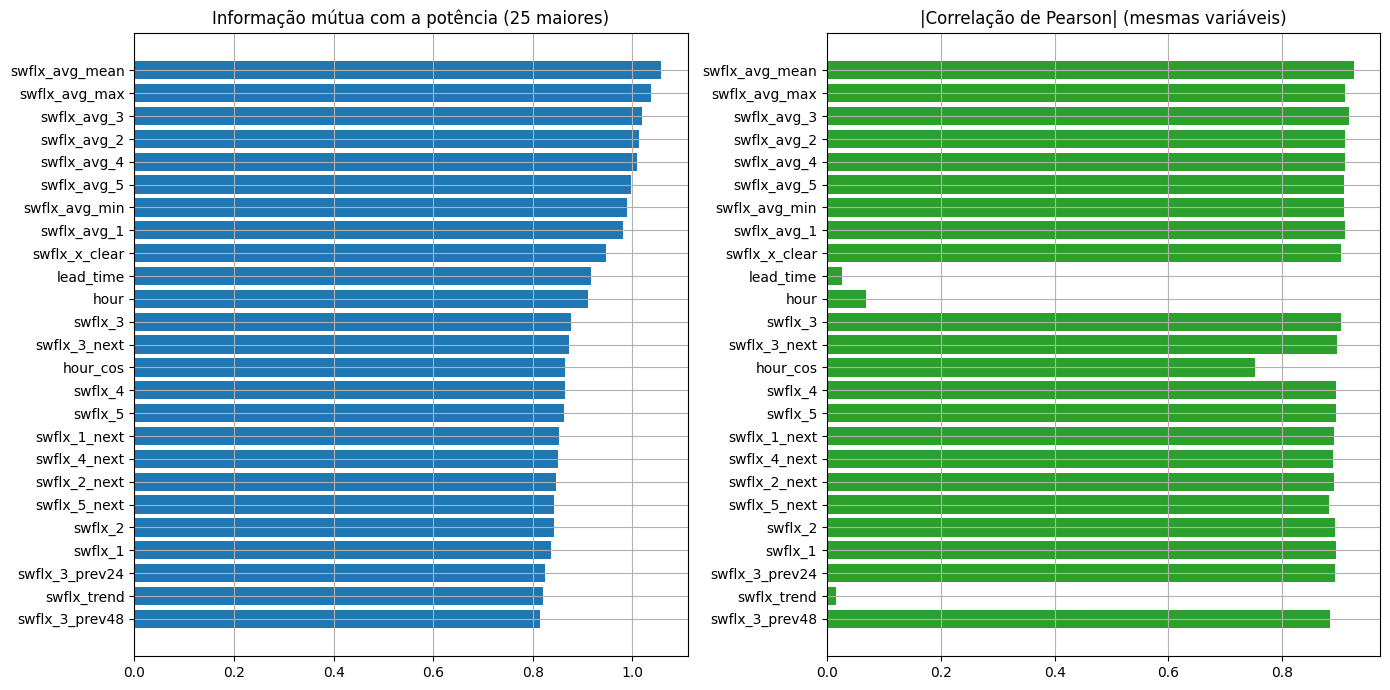

In [120]:
from sklearn.feature_selection import mutual_info_regression

cands = [c for c in feat_cols if not c.startswith('hour_') or c in ('hour_sin', 'hour_cos')]
cands = [c for c in cands if c not in ('no_prev_run',)]
Xc = data24[cands].astype(float)
yc = data24['power']

rel = pd.DataFrame({'pearson':  Xc.corrwith(yc),
                    'spearman': Xc.corrwith(yc, method='spearman')})
rel['|pearson|'] = rel['pearson'].abs()
rel['MI'] = mutual_info_regression(Xc.fillna(0), yc, random_state=SEED)
rel = rel.sort_values('MI', ascending=False)

top = rel.head(25)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].barh(top.index, top['MI'], color='C0'); ax[0].set(title='Informação mútua com a potência (25 maiores)')
ax[1].barh(top.index, top['|pearson|'], color='C2'); ax[1].set(title='|Correlação de Pearson| (mesmas variáveis)')
plt.tight_layout()
display(rel.head(15).round(3))

In [ ]:
# Variáveis muito redundantes entre si (|r| > 0.98) são candidatas a remover
cm = Xc.corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
           .loc[lambda s: s > 0.98].sort_values(ascending=False))
print('Pares com |r| > 0.98:', len(pairs))
display(pairs.head(15).round(4).to_frame('|r|'))

Pares com |r| > 0.98: 10


,,|r|
month,doy,0.9964
swflx_avg_3,swflx_avg_mean,0.9903
swflx_avg_1,swflx_avg_2,0.9896
swflx_avg_4,swflx_avg_mean,0.9865
swflx_avg_mean,swflx_avg_max,0.9861
swflx_avg_1,swflx_avg_mean,0.9845
swflx_avg_2,swflx_avg_mean,0.9837
swflx_1,swflx_2,0.9819
swflx_1_next,swflx_2_next,0.9819
swflx_avg_5,swflx_avg_mean,0.9804


---
## 6. Esquema de validação cronológica

In [ ]:
from sklearn.base import clone

def month_folds(train_leads=TRAIN_LEADS):
    #Lista de (mês, índices de treino, índices de validação) da validação em blocos mensais
    folds = []
    for m in sorted(data_all['run_month'].unique()):
        va = data_all.index[(data_all['run_month'] == m) & (data_all['lead_time'] <= MAX_LEAD)]
        hours_val = set(data_all.loc[va, 'timestamp_utc'])
        tr_mask = ((data_all['run_month'] != m) & (data_all['lead_time'] <= train_leads)
                   & ~data_all['timestamp_utc'].isin(hours_val))
        folds.append((m, data_all.index[tr_mask], va))
    return folds

def cv_predict(model, feats, train_leads=TRAIN_LEADS, folds=None):
    '''Previsões out-of-fold para as linhas de data24. `model` é um estimador (ou Pipeline) do scikit-learn.
    Em cada fold o modelo é clonado e ajustado só com o treino desse fold.'''
    folds = folds or month_folds(train_leads)
    oof = pd.Series(np.nan, index=data_all.index)
    for m, tr, va in folds:
        tr = tr[data_all.loc[tr, feats].notna().all(axis=1).values]
        est = clone(model).fit(data_all.loc[tr, feats], data_all.loc[tr, 'power'])
        oof.loc[va] = est.predict(data_all.loc[va, feats])
    return oof.loc[data24.index]

FOLDS = month_folds(TRAIN_LEADS)
fold_tbl = pd.DataFrame([{'fold': i + 1, 'mês de validação': m, 'linhas de treino': len(tr), 'linhas de validação': len(va)}
                         for i, (m, tr, va) in enumerate(FOLDS)]).set_index('fold')
display(fold_tbl.T)

fold,1,2,3,4,5,6,7,8,9,10,11,12
mês de validação,1,2,3,4,5,6,7,8,9,10,11,12
linhas de treino,7462,7534,7510,7486,7486,7486,7726,7462,7486,7462,7510,7656
linhas de validação,744,672,696,720,720,720,480,744,720,744,696,550


Folds válidos: sem sobreposição de runs nem de horas; cada linha de leads 1-24 é validada exatamente uma vez.


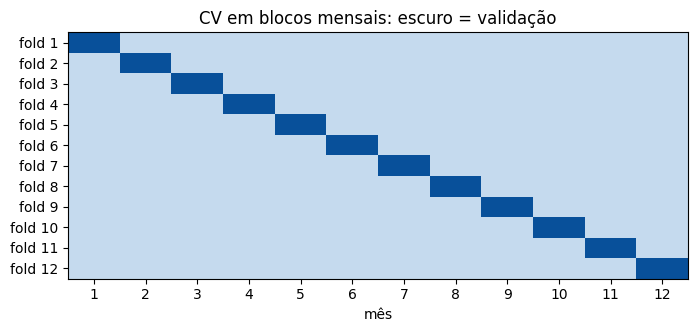

In [123]:
# Verificações: validação e treino nunca partilham runs de validação nem horas de validação
for m, tr, va in FOLDS:
    assert not set(tr) & set(va)
    assert not set(data_all.loc[tr, 'timestamp_utc']) & set(data_all.loc[va, 'timestamp_utc'])
    assert not set(data_all.loc[tr, 'timerequests']) & set(data_all.loc[va, 'timerequests'])
assert sorted(np.concatenate([va for _, _, va in FOLDS])) == sorted(data24.index)   # cada linha validada 1 vez
print('Folds válidos: sem sobreposição de runs nem de horas; cada linha de leads 1-24 é validada exatamente uma vez.')

# Ilustração dos folds (escuro = mês de validação)
fig, ax = plt.subplots(figsize=(8, 3.2))
mat = np.array([[1 if mm == f[0] else 0 for mm in range(1, 13)] for f in FOLDS])
ax.imshow(mat, cmap='Blues', vmin=-0.4, vmax=1.2, aspect='auto'); ax.grid(False)
ax.set(xticks=range(12), xticklabels=range(1, 13), yticks=range(12), yticklabels=[f'fold {i}' for i in range(1, 13)],
       xlabel='mês', title='CV em blocos mensais: escuro = validação')
plt.show()

---
## 7. Benchmarks B0 e B1 e matriz de modelos

In [ ]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import LinearRegression

class Climatology(BaseEstimator, RegressorMixin):
    #B0: média da potência por (mês, hora). Mês ausente do treino -> média dos meses vizinhos; hora ausente -> média global
    def fit(self, X, y):
        d = pd.DataFrame({'m': np.asarray(X['month']), 'h': np.asarray(X['hour']), 'y': np.asarray(y)})
        tab = d.groupby(['m', 'h'])['y'].mean().unstack().reindex(index=range(1, 13), columns=range(24))
        arr = tab.values.copy()
        for i in range(12):
            if np.isnan(arr[i]).all():
                arr[i] = np.nanmean(np.stack([tab.values[(i - 1) % 12], tab.values[(i + 1) % 12]]), axis=0)
        hour_mean = np.nanmean(arr, axis=0)
        arr = np.where(np.isnan(arr), hour_mean[None, :], arr)
        self.table_ = np.where(np.isnan(arr), d['y'].mean(), arr)
        return self
    def predict(self, X):
        return self.table_[np.asarray(X['month']).astype(int) - 1, np.asarray(X['hour']).astype(int)]

class ClipNegative(BaseEstimator, RegressorMixin):
    #Envolve um regressor e põe a 0 as previsões negativas (B1)
    def __init__(self, base=None): self.base = base
    def fit(self, X, y): self.base_ = clone(self.base).fit(X, y); return self
    def predict(self, X): return np.clip(self.base_.predict(X), 0, None)

results = {}                                   # ID -> {'type', 'vars', 'oof'}
def register(id_, model_type, variables, oof):
    results[id_] = {'type': model_type, 'vars': variables, 'oof': oof}

register('B0', 'Climatologia (média mês x hora)', 'month, hour',
         cv_predict(Climatology(), ['month', 'hour']))
register('B1', 'Regressão linear (referência; leads 1-24, negativos = 0)', 'FS1',
         cv_predict(ClipNegative(LinearRegression()), FEATURE_SETS['FS1'], train_leads=24))
print('B0 e B1 calculados:', {k: round(((v['oof'] - y_val) ** 2).mean() / 1e6, 3) for k, v in results.items()}, '(MSE em 10^6 kW^2)')

B0 e B1 calculados: {'B0': np.float64(4.47), 'B1': np.float64(2.97)} (MSE em 10^6 kW^2)


In [ ]:
def model_matrix(results, ref='B1'):
    ref_mse = float(((results[ref]['oof'] - y_val) ** 2).mean())
    rows = []
    for id_, r in results.items():
        m = metrics(y_val, r['oof'], mse_b1=ref_mse)
        rows.append({'ID': id_, 'Model type': r['type'], 'Variables': r['vars'],
                     'MSE (10^6 kW^2)': m['MSE_1e6'], 'RMSE (kW)': m['RMSE'], 'NRMSE (%)': m['NRMSE_%'],
                     'MAE (kW)': m['MAE'], 'bias (kW)': m['bias'], 'Skill vs B1 (%)': m['Skill_vs_B1_%']})
    return pd.DataFrame(rows).set_index('ID')

def post_process(pred, frame):
    #Pós-processamento: noite (swflx = 0 em t e t+1h) = 0 e clip a [0, PMAX]. `frame` tem as colunas swflx_3 e swflx_3_next
    night = (frame['swflx_3'] == 0) & (frame['swflx_3_next'] == 0)
    return pd.Series(np.where(night, 0.0, np.clip(pred, 0, PMAX)), index=pred.index)

matrix = model_matrix(results)
matrix.round(2)

,Model type,Variables,MSE (10^6 kW^2),RMSE (kW),NRMSE (%),MAE (kW),bias (kW),Skill vs B1 (%)
ID,,,,,,,,
B0,Climatologia (média mês x hora),"month, hour",4.47,2114.13,15.62,1228.80,-105.42,-50.51
B1,"Regressão linear (referência; leads 1-24, nega...",FS1,2.97,1723.25,12.74,1023.29,12.89,0.00


---
## 8. Modelos

In [ ]:
from sklearn.model_selection import ParameterGrid
import time

MODELS = {}

def run_models(models, train_leads=None, skip_done=True):
    # Corre a CV de cada modelo e regista-o em results
    # Devolve a matriz atualizada
    tl = TRAIN_LEADS if train_leads is None else train_leads
    for id_, spec in models.items():
        if skip_done and id_ in results:
            continue
        t0 = time.time()
        oof = cv_predict(spec['estimator'], FEATURE_SETS[spec['fs']], train_leads=tl)
        register(id_, spec['type'], spec['fs'], oof)
        print(f"{id_:8s} MSE = {((oof - y_val) ** 2).mean() / 1e6:6.3f} x10^6 kW^2   ({time.time() - t0:.0f} s)")
    return model_matrix(results)

def tune(estimator, grid, fs, train_leads=None):
    # Procura em grelha: devolve uma tabela com o MSE (10^6 kW^2) de cada combinação (mesma CV por mês)
    # grid usa os nomes dos parâmetros do estimador num Pipeline
    tl = TRAIN_LEADS if train_leads is None else train_leads
    rows = []
    for params in ParameterGrid(grid):
        oof = cv_predict(clone(estimator).set_params(**params), FEATURE_SETS[fs], train_leads=tl)
        rows.append({**params, 'MSE (10^6 kW^2)': ((oof - y_val) ** 2).mean() / 1e6})
    return pd.DataFrame(rows).sort_values('MSE (10^6 kW^2)').reset_index(drop=True)

if MODELS:
    run_models(MODELS)
else:
    print('MODELS está vazio: define os teus modelos acima e volta a correr esta célula.')

MODELS está vazio: define os teus modelos acima e volta a correr esta célula.


### 8.1 Procura de hiperparâmetros

In [ ]:
from sklearn.model_selection import GroupKFold, ParameterSampler
from scipy.stats import loguniform, randint, uniform

SEARCH_SPLITS = 4

def grouped_folds(n_splits=SEARCH_SPLITS, train_leads=None):
    #Folds de procura: GroupKFold por mês do run (validação = leads 1-24; treino sem as horas de validação)
    tl = TRAIN_LEADS if train_leads is None else train_leads
    folds = []
    for k, (_, va_pos) in enumerate(GroupKFold(n_splits=n_splits).split(data24, groups=data24['run_month'])):
        months = set(data24['run_month'].iloc[va_pos])
        va = data_all.index[data_all['run_month'].isin(months) & (data_all['lead_time'] <= MAX_LEAD)]
        hours_val = set(data_all.loc[va, 'timestamp_utc'])
        tr = data_all.index[~data_all['run_month'].isin(months) & (data_all['lead_time'] <= tl)
                            & ~data_all['timestamp_utc'].isin(hours_val)]
        folds.append((sorted(months), tr, va))
    return folds

def random_search(estimator, dist, fs, n_iter=10, n_splits=SEARCH_SPLITS, seed=SEED, train_leads=None):
    # Procura aleatória com a CV de procura. Devolve (tabela ordenada, melhores parâmetros).
    tl = TRAIN_LEADS if train_leads is None else train_leads
    folds = grouped_folds(n_splits, tl)
    rows = []
    for params in ParameterSampler(dist, n_iter=n_iter, random_state=seed):
        t0 = time.time()
        oof = cv_predict(clone(estimator).set_params(**params), FEATURE_SETS[fs], train_leads=tl, folds=folds)
        rows.append({**params, 'MSE (10^6 kW^2)': float(((oof - y_val) ** 2).mean()) / 1e6, 'tempo (s)': time.time() - t0})
    tbl = pd.DataFrame(rows).sort_values('MSE (10^6 kW^2)').reset_index(drop=True)
    best = {k: tbl.loc[0, k] for k in rows[0] if k not in ('MSE (10^6 kW^2)', 'tempo (s)')}
    best = {k: (v.item() if hasattr(v, 'item') else v) for k, v in best.items()}
    return tbl, best

SEARCH_FOLDS = grouped_folds()
print('Folds de procura (meses de validação):', [f[0] for f in SEARCH_FOLDS])

Folds de procura (meses de validação): [[6, 10, 12], [5, 7, 8], [1, 3, 11], [2, 4, 9]]


### 8.2 Modelos M1–M7

In [128]:
# ---- M1: regressão linear múltipla (FS2) ------------------------------------------------------
MODELS['M1'] = dict(type='Regressão linear múltipla', fs='FS2', estimator=LinearRegression())

In [129]:
# ---- M3: Ridge com alpha escolhido em grelha (12 folds, é rápido) ----------------------------
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge = make_pipeline(StandardScaler(), Ridge())
ridge_tbl = tune(ridge, {'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]}, 'FS4')
display(ridge_tbl.round(4))
best_alpha = float(ridge_tbl.loc[0, 'ridge__alpha'])
MODELS['M3'] = dict(type=f'Ridge (alpha={best_alpha:g})', fs='FS4',
                    estimator=make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)))

,ridge__alpha,MSE (10^6 kW^2)
0,100.00,1.7752
1,10.00,1.7787
2,1.00,1.7797
3,0.10,1.7798
4,0.01,1.7798
5,1000.00,1.8066


In [130]:
# ---- M4: random forest (procura aleatória, 4 folds) -------------------------------------------
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)
rf_dist = {'max_depth': randint(6, 17), 'min_samples_leaf': randint(3, 31), 'max_features': uniform(0.3, 0.4)}
rf_tbl, rf_best = random_search(rf, rf_dist, 'FS4', n_iter=8)
display(rf_tbl.round(3).head(5))
print('Melhor:', {k: round(v, 3) if isinstance(v, float) else v for k, v in rf_best.items()})
MODELS['M4'] = dict(type=f"Random forest (300 árvores, prof. {rf_best['max_depth']}, folha {rf_best['min_samples_leaf']}, "
                         f"max_features {rf_best['max_features']:.2f})",
                    fs='FS4', estimator=clone(rf).set_params(**rf_best))

KeyboardInterrupt: 

In [ ]:
# ---- M5: gradient boosting (intervalos do notebook 04) ----------------------------------------
from sklearn.ensemble import GradientBoostingRegressor
gbr = GradientBoostingRegressor(random_state=SEED)
gbr_dist = {'n_estimators': randint(100, 600), 'learning_rate': loguniform(0.01, 0.3), 'max_depth': randint(2, 6),
            'min_samples_leaf': randint(5, 100), 'subsample': uniform(0.5, 0.5)}
gbr_tbl, gbr_best = random_search(gbr, gbr_dist, 'FS4', n_iter=12)
display(gbr_tbl.round(3).head(5))
print('Melhor:', {k: round(v, 3) if isinstance(v, float) else v for k, v in gbr_best.items()})
MODELS['M5'] = dict(type=(f"Gradient boosting ({gbr_best['n_estimators']} árvores, lr {gbr_best['learning_rate']:.3f}, "
                          f"prof. {gbr_best['max_depth']}, folha {gbr_best['min_samples_leaf']}, subsample {gbr_best['subsample']:.2f})"),
                    fs='FS4', estimator=clone(gbr).set_params(**gbr_best))

,learning_rate,max_depth,min_samples_leaf,n_estimators,subsample,MSE (10^6 kW^2),tempo (s)
0,0.012,5,84,370,0.728,1.603,53.465
1,0.076,3,87,314,0.529,1.666,22.967
2,0.102,5,12,530,0.587,1.702,72.674
3,0.144,4,59,343,0.796,1.718,48.529
4,0.028,2,6,439,0.621,1.731,26.987


Melhor: {'learning_rate': 0.012, 'max_depth': 5, 'min_samples_leaf': 84, 'n_estimators': 370, 'subsample': 0.728}


In [ ]:
# ---- M6: MLP (entradas e alvo normalizados) --------------------------
import warnings
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

def make_ann(**params):
    mlp = MLPRegressor(activation='relu', solver='adam', max_iter=1000, early_stopping=True, random_state=SEED, **params)
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), mlp), transformer=StandardScaler())

mlp_key = 'regressor__mlpregressor__'
mlp_dist = {mlp_key + 'hidden_layer_sizes': [(10,), (20,), (20, 10), (32, 16), (64, 32)],
            mlp_key + 'alpha': loguniform(1e-4, 1),
            mlp_key + 'learning_rate_init': loguniform(1e-4, 1e-1)}
mlp_tbl, mlp_best = random_search(make_ann(), mlp_dist, 'FS4', n_iter=8)
display(mlp_tbl.round(4).head(5))
short = {k.split('__')[-1]: (round(v, 5) if isinstance(v, float) else v) for k, v in mlp_best.items()}
print('Melhor:', short)
MODELS['M6'] = dict(type=f"MLP {short['hidden_layer_sizes']} (alpha {short['alpha']:.4g}, lr {short['learning_rate_init']:.4g})",
                    fs='FS4', estimator=make_ann().set_params(**mlp_best))

,regressor__mlpregressor__alpha,regressor__mlpregressor__hidden_layer_sizes,regressor__mlpregressor__learning_rate_init,MSE (10^6 kW^2),tempo (s)
0,0.0022,"(20, 10)",0.0001,1.5129,18.0095
1,0.0015,"(20, 10)",0.0016,1.5467,4.0262
2,0.0004,"(20, 10)",0.0024,1.5497,2.7963
3,0.7579,"(32, 16)",0.0654,1.5551,1.8855
4,0.1315,"(64, 32)",0.0003,1.5847,6.8889


Melhor: {'alpha': 0.00216, 'hidden_layer_sizes': (20, 10), 'learning_rate_init': 0.00012}


### 8.3 Avaliação com a validação cruzada de 12 folds (valores da matriz)

In [ ]:
run_models(MODELS)            # CV mensal de 12 folds; regista M1, M3, M4, M5, M6 em `results`

M1       MSE =  2.009 x10^6 kW^2   (0 s)
M3       MSE =  1.775 x10^6 kW^2   (1 s)
M4       MSE =  1.548 x10^6 kW^2   (14 s)
M5       MSE =  1.568 x10^6 kW^2   (209 s)
M6       MSE =  1.495 x10^6 kW^2   (49 s)


,Model type,Variables,MSE (10^6 kW^2),RMSE (kW),NRMSE (%),MAE (kW),bias (kW),Skill vs B1 (%)
ID,,,,,,,,
B0,Climatologia (média mês x hora),"month, hour",4.469530,2114.126317,15.624317,1228.796253,-105.422888,-50.509217
B1,"Regressão linear (referência; leads 1-24, nega...",FS1,2.969606,1723.254356,12.735602,1023.290494,12.893223,0.000000
M1,Regressão linear múltipla,FS2,2.009331,1417.508871,10.476010,803.235503,13.282365,32.336758
M3,Ridge (alpha=100),FS4,1.775159,1332.350951,9.846655,789.885829,3.688450,40.222396
M4,"Random forest (300 árvores, prof. 9, folha 5, ...",FS4,1.547542,1244.002341,9.193721,594.879835,0.603058,47.887294
M5,"Gradient boosting (370 árvores, lr 0.012, prof...",FS4,1.568179,1252.269667,9.254820,617.182852,9.285250,47.192337
M6,"MLP (20, 10) (alpha 0.00216, lr 0.00012)",FS4,1.494759,1222.603208,9.035572,653.086818,-2.192078,49.664743


### 8.4 M7 (média dos modelos) e pós-processamento

In [ ]:
ENS_IDS = ['M4', 'M5', 'M6']
ENS_WEIGHTS = [1 / len(ENS_IDS)] * len(ENS_IDS)

class SubsetEnsemble(BaseEstimator, RegressorMixin):
    # Média ponderada de modelos, cada um com o seu feature set
    # Recebe um DataFrame com a união das colunas
    def __init__(self, members=None, weights=None):
        self.members, self.weights = members, weights
    def fit(self, X, y):
        self.fitted_ = [(clone(est).fit(X[cols], y), cols) for est, cols in self.members]
        return self
    def predict(self, X):
        preds = np.column_stack([est.predict(X[cols]) for est, cols in self.fitted_])
        return preds @ np.asarray(self.weights)

FEATURE_SETS['FS_ENS'] = uniq(sum([FEATURE_SETS[MODELS[i]['fs']] for i in ENS_IDS], []))
MODELS['M7'] = dict(type='Média de ' + ' + '.join(ENS_IDS), fs='FS_ENS',
                    estimator=SubsetEnsemble(members=[(MODELS[i]['estimator'], FEATURE_SETS[MODELS[i]['fs']]) for i in ENS_IDS],
                                             weights=ENS_WEIGHTS))
oof_ens = sum(w * results[i]['oof'] for w, i in zip(ENS_WEIGHTS, ENS_IDS))
register('M7', MODELS['M7']['type'], 'FS_ENS', oof_ens)

# pós-processamento de todos os modelos (apaga PP_IDS se não quiseres tantas linhas na matriz)
PP_IDS = ['M1', 'M3', 'M4', 'M5', 'M6', 'M7']
for i in PP_IDS:
    register(f'{i}-PP', results[i]['type'] + ' + pós-proc. (noite=0, clip)', results[i]['vars'],
             post_process(results[i]['oof'], data24))
model_matrix(results).round(3)

,Model type,Variables,MSE (10^6 kW^2),RMSE (kW),NRMSE (%),MAE (kW),bias (kW),Skill vs B1 (%)
ID,,,,,,,,
B0,Climatologia (média mês x hora),"month, hour",4.470,2114.126,15.624,1228.796,-105.423,-50.509
B1,"Regressão linear (referência; leads 1-24, nega...",FS1,2.970,1723.254,12.736,1023.290,12.893,0.000
M1,Regressão linear múltipla,FS2,2.009,1417.509,10.476,803.236,13.282,32.337
M3,Ridge (alpha=100),FS4,1.775,1332.351,9.847,789.886,3.688,40.222
M4,"Random forest (300 árvores, prof. 9, folha 5, ...",FS4,1.548,1244.002,9.194,594.880,0.603,47.887
M5,"Gradient boosting (370 árvores, lr 0.012, prof...",FS4,1.568,1252.270,9.255,617.183,9.285,47.192
M6,"MLP (20, 10) (alpha 0.00216, lr 0.00012)",FS4,1.495,1222.603,9.036,653.087,-2.192,49.665
M9,"MLP (20, 10) FS4, média de 10 sementes",FS4,1.413,1188.906,8.787,572.830,0.781,52.401
M7,Média de M4 + M5 + M6,FS_ENS,1.464,1209.949,8.942,599.401,2.565,50.701


---
## 9. Matriz de modelos

,Model type,Variables,MSE (10^6 kW^2),RMSE (kW),NRMSE (%),MAE (kW),bias (kW),Skill vs B1 (%)
ID,,,,,,,,
B0,Climatologia (média mês x hora),"month, hour",4.47,2114.13,15.62,1228.80,-105.42,-50.51
B1,"Regressão linear (referência; leads 1-24, nega...",FS1,2.97,1723.25,12.74,1023.29,12.89,0.00
M1,Regressão linear múltipla,FS2,2.01,1417.51,10.48,803.24,13.28,32.34
M3,Ridge (alpha=100),FS4,1.78,1332.35,9.85,789.89,3.69,40.22
M4,"Random forest (300 árvores, prof. 9, folha 5, ...",FS4,1.55,1244.00,9.19,594.88,0.60,47.89
M5,"Gradient boosting (370 árvores, lr 0.012, prof...",FS4,1.57,1252.27,9.25,617.18,9.29,47.19
M6,"MLP (20, 10) (alpha 0.00216, lr 0.00012)",FS4,1.49,1222.60,9.04,653.09,-2.19,49.66
M9,"MLP (20, 10) FS4, média de 10 sementes",FS4,1.41,1188.91,8.79,572.83,0.78,52.40
M7,Média de M4 + M5 + M6,FS_ENS,1.46,1209.95,8.94,599.40,2.57,50.70


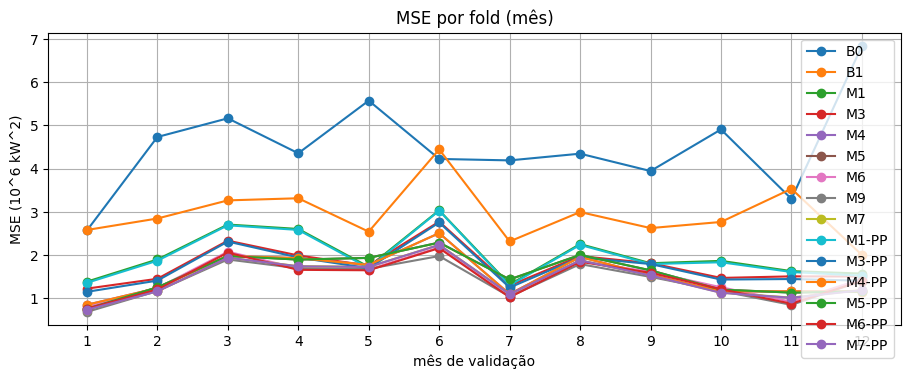

In [ ]:
matrix = model_matrix(results)
matrix.to_csv('model_matrix.csv', sep=';', float_format='%.4f')
display(matrix.round(2))

def fold_mse(results):
    #MSE (10^6 kW^2) de cada modelo em cada mês de validação: mostra a estabilidade entre folds
    month = data24['run_month']
    return pd.DataFrame({k: ((r['oof'] - y_val) ** 2).groupby(month).mean() / 1e6 for k, r in results.items()})

fm = fold_mse(results)
ax = fm.plot(marker='o', figsize=(11, 3.8))
ax.set(xlabel='mês de validação', ylabel='MSE (10^6 kW^2)', title='MSE por fold (mês)', xticks=range(1, 13))
plt.show()

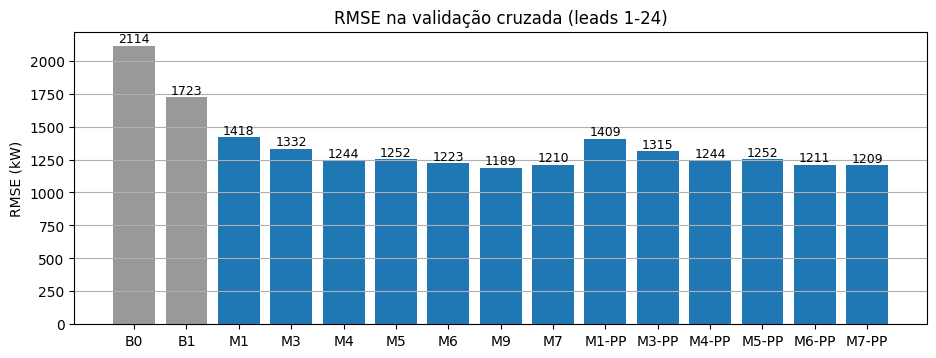

In [ ]:
# RMSE por modelo (cinzento = benchmarks)
fig, ax = plt.subplots(figsize=(11, 3.8))
cols = ['0.6' if i in ('B0', 'B1') else 'C0' for i in matrix.index]
ax.bar(matrix.index, matrix['RMSE (kW)'], color=cols)
for i, v in enumerate(matrix['RMSE (kW)']):
    ax.text(i, v, f'{v:.0f}', ha='center', va='bottom', fontsize=9)
ax.set(ylabel='RMSE (kW)', title='RMSE na validação cruzada (leads 1-24)'); ax.grid(axis='x')
plt.show()

---
## 10. Análise de erros

Erro = previsto − observado (positivo = sobrestima)

In [ ]:
ANALYSIS_IDS = list(dict.fromkeys(['B1'] + [i for i in results if i not in ('B0', 'B1')][-2:]))   # <-- ajusta
print('Modelos analisados:', ANALYSIS_IDS)

res = data24[['timerequests', 'timestamp_utc', 'lead_time', 'hour', 'month', 'power', 'swflx_3', 'swflx_3_next',
              'cft_avg_3']].copy()
for i in ANALYSIS_IDS:
    res[i] = results[i]['oof']
    res[f'err_{i}'] = res[i] - res['power']

rmse = lambda e: float(np.sqrt(np.mean(np.asarray(e) ** 2)))

Modelos analisados: ['B1', 'M6-PP', 'M7-PP']


### 10.1 Erro por lead time (= hora do dia)

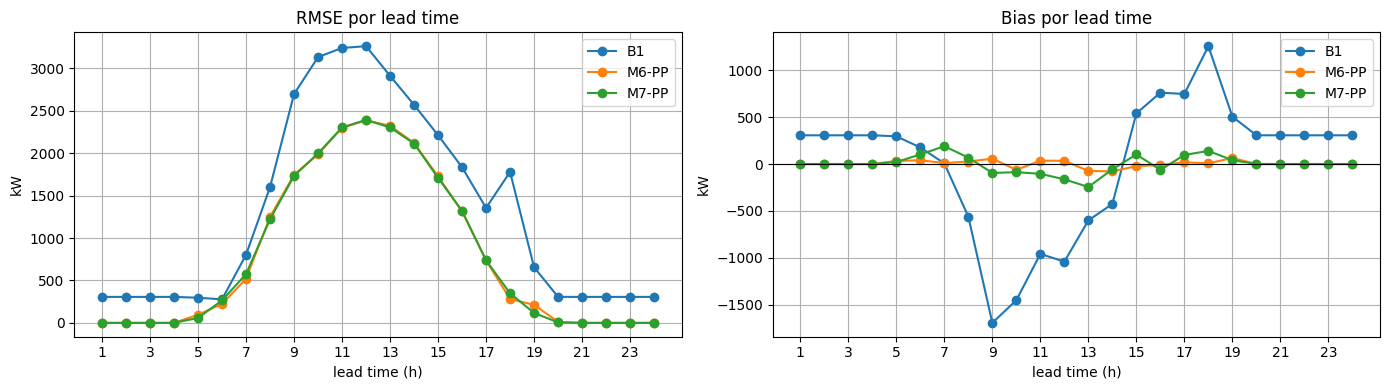

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, i in enumerate(ANALYSIS_IDS):
    g = res.groupby('lead_time')[f'err_{i}']
    ax[0].plot(g.apply(rmse), marker='o', color=f'C{k}', label=i)
    ax[1].plot(g.mean(), marker='o', color=f'C{k}', label=i)
ax[0].set(title='RMSE por lead time', xlabel='lead time (h)', ylabel='kW', xticks=range(1, 25, 2))
ax[1].set(title='Bias por lead time', xlabel='lead time (h)', ylabel='kW', xticks=range(1, 25, 2))
ax[1].axhline(0, color='k', lw=0.8); ax[0].legend(); ax[1].legend()
plt.tight_layout()

### 10.2 Por mês e por tipo de dia

In [ ]:
SKY_PARAMS = dict(clear_ratio=0.85, clear_tv=1.15, overcast_ratio=0.30)

def classify_days(hourly_power, p=SKY_PARAMS):
    d = hourly_power[(hourly_power.index.hour >= 6) & (hourly_power.index.hour <= 18)]
    g = d.groupby(d.index.normalize())
    valid = g.count() == 13
    energy = g.sum().where(valid)
    env = energy.rolling(31, center=True, min_periods=10).quantile(0.95)
    tv = g.apply(lambda s: np.abs(np.diff(s.values)).sum() / (2 * np.nanmax(s.values)) if np.nanmax(s.values) > 0 else np.nan)
    days = pd.DataFrame({'energy': energy, 'ratio': energy / env, 'TV': tv.where(valid)}).dropna()
    days['sky'] = np.where((days['ratio'] >= p['clear_ratio']) & (days['TV'] <= p['clear_tv']), 'clear',
                    np.where(days['ratio'] < p['overcast_ratio'], 'overcast', 'variable'))
    return days

days = classify_days(hourly['power'])
print(days['sky'].value_counts().to_dict())
res['sky'] = res['timestamp_utc'].dt.normalize().map(days['sky'])

{'clear': 154, 'variable': 143, 'overcast': 45}


sky,clear,variable,overcast
horas,3693,3431,1078


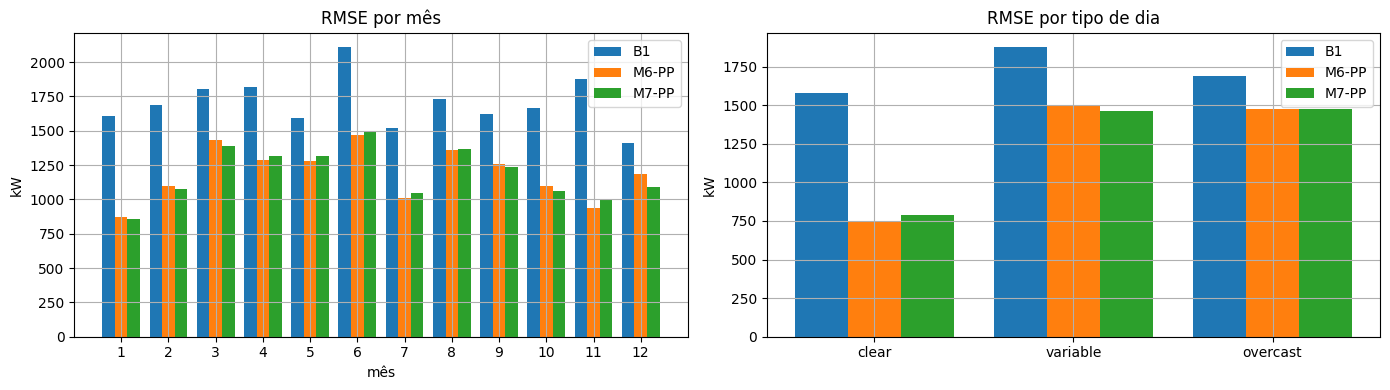

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(1, 13); w = 0.8 / len(ANALYSIS_IDS)
for k, i in enumerate(ANALYSIS_IDS):
    by_m = res.groupby('month')[f'err_{i}'].apply(rmse)
    ax[0].bar(x + (k - (len(ANALYSIS_IDS) - 1) / 2) * w, by_m.reindex(x), w, color=f'C{k}', label=i)
ax[0].set(title='RMSE por mês', xlabel='mês', ylabel='kW', xticks=x); ax[0].legend()

order = ['clear', 'variable', 'overcast']
xs = np.arange(3)
for k, i in enumerate(ANALYSIS_IDS):
    by_s = res.dropna(subset=['sky']).groupby('sky')[f'err_{i}'].apply(rmse).reindex(order)
    ax[1].bar(xs + (k - (len(ANALYSIS_IDS) - 1) / 2) * w, by_s, w, color=f'C{k}', label=i)
ax[1].set(title='RMSE por tipo de dia', xticks=xs, xticklabels=order, ylabel='kW'); ax[1].legend()
plt.tight_layout()
display(res.dropna(subset=['sky']).groupby('sky').size().reindex(order).rename('horas').to_frame().T)

### 10.3 Observado vs previsto em dias típicos

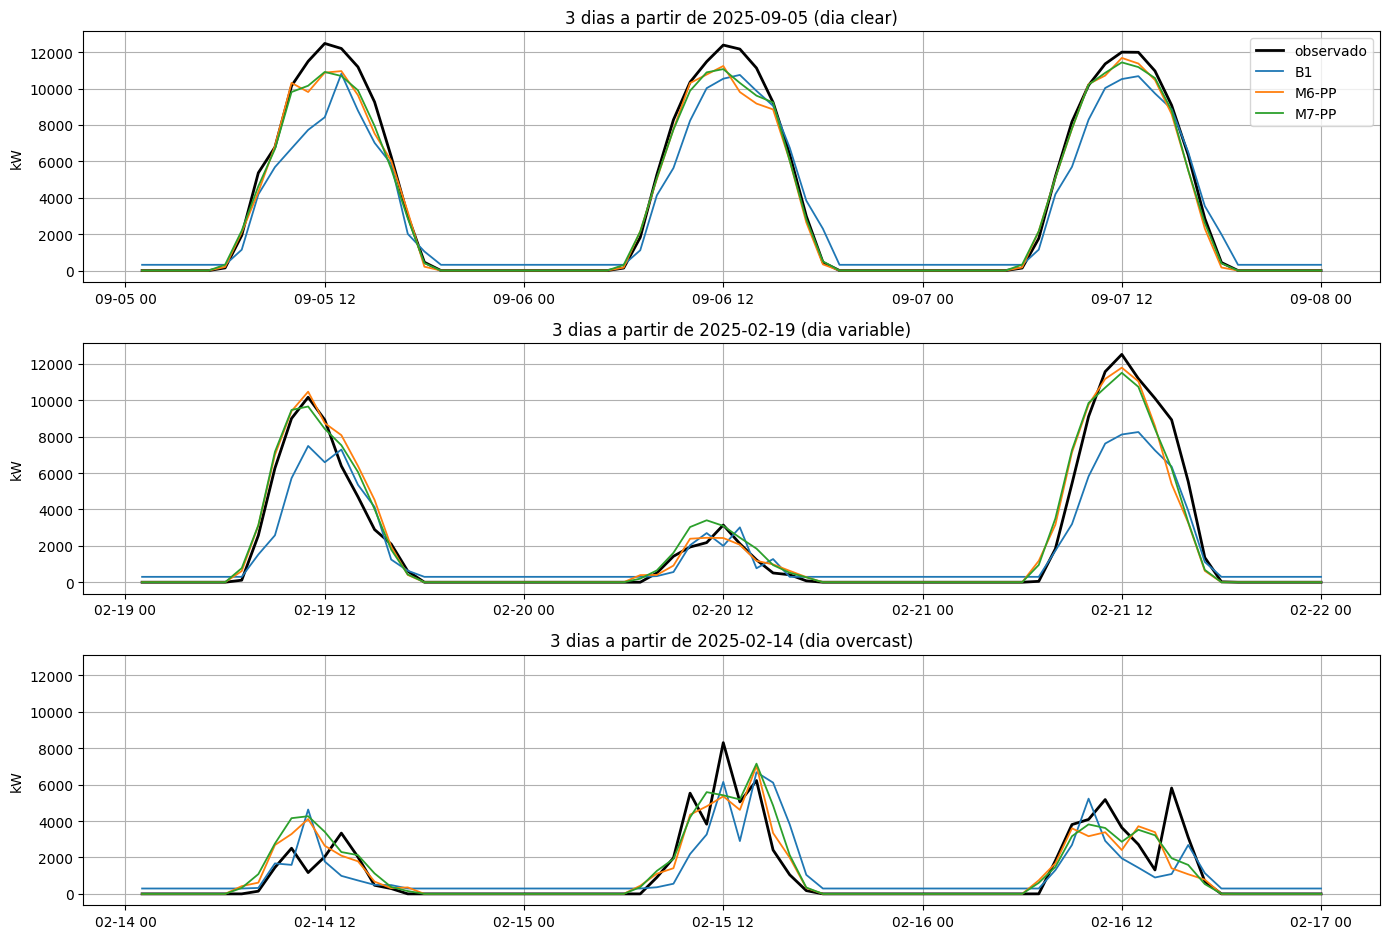

In [ ]:
CASE_DAYS = {}
for sky in ['clear', 'variable', 'overcast']:
    if sky not in CASE_DAYS:
        d = days[days['sky'] == sky]
        CASE_DAYS[sky] = (d['ratio'] - d['ratio'].median()).abs().idxmin()

fig, axes = plt.subplots(3, 1, figsize=(14, 9.5), sharey=True)
for ax, sky in zip(axes, ['clear', 'variable', 'overcast']):
    d0 = pd.Timestamp(CASE_DAYS[sky])
    w_ = res[(res['timestamp_utc'] > d0) & (res['timestamp_utc'] <= d0 + pd.Timedelta(days=3))]
    ax.plot(w_['timestamp_utc'], w_['power'], 'k', lw=2, label='observado')
    for k, i in enumerate(ANALYSIS_IDS):
        ax.plot(w_['timestamp_utc'], w_[i], color=f'C{k}', lw=1.3, label=i)
    ax.set(title=f'3 dias a partir de {d0.date()} (dia {sky})', ylabel='kW')
axes[0].legend(loc='upper right'); plt.tight_layout()

### 10.4 Previsto vs observado (dispersão) e distribuição dos erros

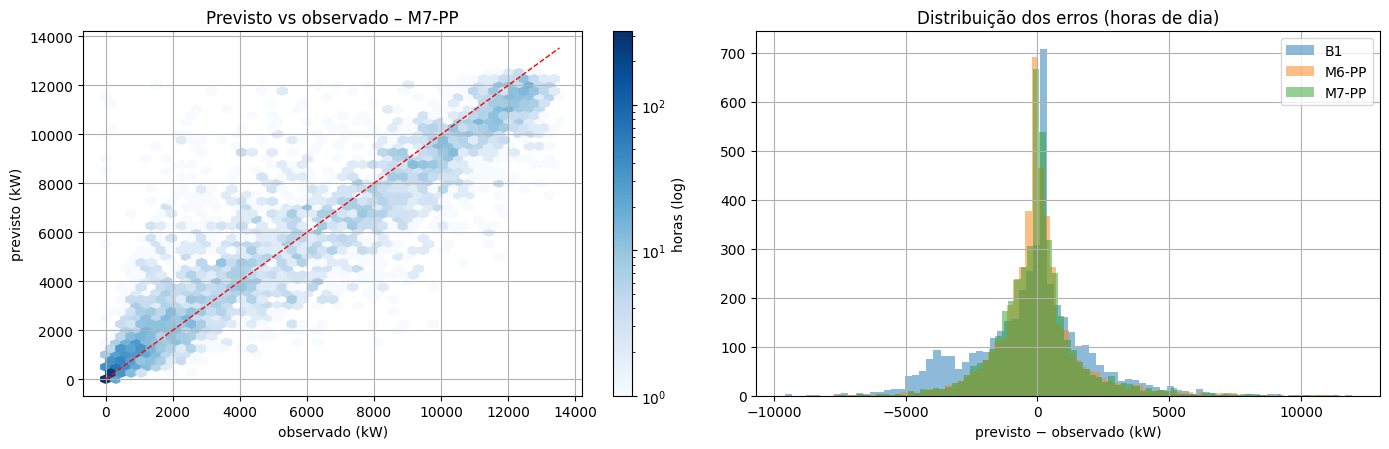

In [ ]:
i = ANALYSIS_IDS[-1]
day_rows = res[(res['power'] > 0) | (res[i] > 0)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
hb = ax[0].hexbin(day_rows['power'], day_rows[i], gridsize=45, cmap='Blues', mincnt=1, bins='log')
ax[0].plot([0, PMAX], [0, PMAX], 'r--', lw=1)
ax[0].set(xlabel='observado (kW)', ylabel='previsto (kW)', title=f'Previsto vs observado – {i}'); fig.colorbar(hb, ax=ax[0], label='horas (log)')
for k, j in enumerate(ANALYSIS_IDS):
    ax[1].hist(day_rows[f'err_{j}'], bins=80, alpha=0.5, color=f'C{k}', label=j)
ax[1].set(title='Distribuição dos erros (horas de dia)', xlabel='previsto − observado (kW)'); ax[1].legend()
plt.tight_layout()

### 10.5 Nascer e pôr do sol, nebulosidade e *overfitting*

In [ ]:
# Erro (RMSE e bias) por nível de nebulosidade prevista (cft_avg_3) nas horas de dia
day = res[(res['swflx_3'] > 0) | (res['swflx_3_next'] > 0)].copy()
day['nebulosidade'] = pd.cut(day['cft_avg_3'], [-0.01, 0.2, 0.5, 0.8, 1.0], labels=['<=0.2', '0.2-0.5', '0.5-0.8', '>0.8'])
tab = pd.concat({f'RMSE {i}': day.groupby('nebulosidade', observed=True)[f'err_{i}'].apply(rmse) for i in ANALYSIS_IDS}
                | {f'bias {i}': day.groupby('nebulosidade', observed=True)[f'err_{i}'].mean() for i in ANALYSIS_IDS}, axis=1)
display(tab.round(0))

# Nascer/pôr do sol: horas em que a irradiância prevista é baixa (< 100 W/m²)
edge = day[day['swflx_3'].between(0, 100)]
print('Linhas com swflx_3 entre 0 e 100 W/m²:', len(edge))
display(pd.Series({f'RMSE {i}': rmse(edge[f'err_{i}']) for i in ANALYSIS_IDS}).round(0).to_frame('kW').T)

,RMSE B1,RMSE M6-PP,RMSE M7-PP,bias B1,bias M6-PP,bias M7-PP
nebulosidade,,,,,,
<=0.2,2333.0,1490.0,1501.0,-252.0,0.0,-20.0
0.2-0.5,2662.0,2078.0,2060.0,-127.0,49.0,56.0
0.5-0.8,1928.0,1588.0,1584.0,-463.0,-73.0,-64.0
>0.8,1726.0,1460.0,1353.0,-562.0,154.0,76.0


Linhas com swflx_3 entre 0 e 100 W/m²: 1384


,RMSE B1,RMSE M6-PP,RMSE M7-PP
kW,1426.0,1043.0,976.0


In [ ]:
def train_vs_cv(model, fs, train_leads=None, id_=None):
    # MSE (10^6 kW^2) no treino (modelo ajustado com TODO o treino, avaliado nas mesmas linhas) vs MSE na CV.
    # Uma grande diferença sugere overfitting
    tl = TRAIN_LEADS if train_leads is None else train_leads
    feats = FEATURE_SETS[fs]
    tr = data_all[data_all['lead_time'] <= tl]
    tr = tr[tr[feats].notna().all(axis=1)]
    est = clone(model).fit(tr[feats], tr['power'])
    in_mse = float(((est.predict(data24[feats]) - y_val) ** 2).mean()) / 1e6
    oof = results[id_]['oof'] if id_ in results else cv_predict(model, feats, train_leads=tl)   # reutiliza a CV já feita
    cv_mse = float(((oof - y_val) ** 2).mean()) / 1e6
    return {'MSE treino': in_mse, 'MSE CV': cv_mse, 'rácio CV/treino': cv_mse / in_mse}

if MODELS:
    display(pd.DataFrame({i: train_vs_cv(s['estimator'], s['fs'], id_=i) for i, s in MODELS.items()}).T.round(3))

,MSE treino,MSE CV,rácio CV/treino
M1,1.929,2.009,1.042
M3,1.637,1.775,1.084
M4,0.726,1.548,2.132
M5,0.991,1.568,1.583
M6,1.249,1.495,1.197
M9,1.161,1.413,1.218
M7,0.934,1.464,1.568


---
## 11. Escolha do modelo final

In [ ]:
fm = fold_mse(results)
sel = model_matrix(results)[['Model type', 'Variables', 'MSE (10^6 kW^2)', 'Skill vs B1 (%)']].copy()
sel['std MSE entre folds'] = fm.std()
sel['pior fold (mês)'] = fm.idxmax()
sel['nº features'] = [len(FEATURE_SETS[v]) if v in FEATURE_SETS else np.nan for v in sel['Variables']]
display(sel.sort_values('MSE (10^6 kW^2)').round(3))

,Model type,Variables,MSE (10^6 kW^2),Skill vs B1 (%),std MSE entre folds,pior fold (mês),nº features
ID,,,,,,,
M9,"MLP (20, 10) FS4, média de 10 sementes",FS4,1.413,52.401,0.423,6,51.0
M7-PP,"Média de M4 + M5 + M6 + pós-proc. (noite=0, clip)",FS_ENS,1.461,50.806,0.456,6,51.0
M7,Média de M4 + M5 + M6,FS_ENS,1.464,50.701,0.455,6,51.0
M6-PP,"MLP (20, 10) (alpha 0.00216, lr 0.00012) + pós...",FS4,1.465,50.656,0.452,6,51.0
M6,"MLP (20, 10) (alpha 0.00216, lr 0.00012)",FS4,1.495,49.665,0.444,6,51.0
M4,"Random forest (300 árvores, prof. 9, folha 5, ...",FS4,1.548,47.887,0.497,6,51.0
M4-PP,"Random forest (300 árvores, prof. 9, folha 5, ...",FS4,1.548,47.887,0.497,6,51.0
M5-PP,"Gradient boosting (370 árvores, lr 0.012, prof...",FS4,1.568,47.212,0.466,6,51.0
M5,"Gradient boosting (370 árvores, lr 0.012, prof...",FS4,1.568,47.192,0.466,6,51.0


In [ ]:
# ---- MODELO FINAL ----------------------------------------------------------------------

FINAL = dict(
    id          = 'M7-PP',                       # linha da matriz escolhida
    estimator   = MODELS['M7']['estimator'],     # SubsetEnsemble: média de M4, M5 e M6
    fs          = 'FS_ENS',                      # união dos feature sets dos três modelos
    train_leads = 24,                            # leads usados no ajuste final (igual a TRAIN_LEADS)
    postprocess = True,                          # noite = 0 e clip a [0, PMAX]
)
# ------------------------------------------------------------------------------------------------
feats_final = FEATURE_SETS[FINAL['fs']]
fit_rows = data_all[data_all['lead_time'] <= FINAL['train_leads']]
fit_rows = fit_rows[fit_rows[feats_final].notna().all(axis=1)]
final_model = clone(FINAL['estimator']).fit(fit_rows[feats_final], fit_rows['power'])      # TODO o treino
print(f"Modelo final {FINAL['id']} ajustado com {len(fit_rows):,} linhas, {len(feats_final)} features ({FINAL['fs']}).")

oof_final = results[FINAL['id']]['oof'] if FINAL['id'] in results else None
if oof_final is not None:
    pred_cv = post_process(oof_final, data24) if FINAL['postprocess'] else oof_final
    mse_exp = float(((pred_cv - y_val) ** 2).mean()) / 1e6
    print(f'MSE esperado no teste (o da validação cruzada, {"com" if FINAL["postprocess"] else "sem"} pós-proc.): {mse_exp:.3f} x10^6 kW^2')
else:
    print('O ID escolhido ainda não está em `results`: regista-o com register() para teres o MSE esperado.')
if FINAL['id'] in ('B0', 'B1'):
    print('AVISO: o modelo final é um benchmark (substituto). Escolhe um dos teus modelos antes de submeter.')

Modelo final M7-PP ajustado com 8,206 linhas, 51 features (FS_ENS).
MSE esperado no teste (o da validação cruzada, com pós-proc.): 1.461 x10^6 kW^2


---
## 12. Previsão para o teste e ficheiro de submissão

In [ ]:
X_test = test_X[feats_final]
assert X_test.notna().all().all(), 'há NaN nas features do teste'
pred_test = pd.Series(final_model.predict(X_test), index=test_X.index)
pred_test = post_process(pred_test, test_X) if FINAL['postprocess'] else pred_test.clip(lower=0)   # nunca negativo
assert pred_test.notna().all() and (pred_test >= 0).all()

sub = pd.DataFrame({'timerequests': test_X['timerequests'].dt.strftime('%d/%m/%Y %H:%M'),
                    'timestamp_utc': test_X['timestamp_utc'].dt.strftime('%d/%m/%Y %H:%M'),
                    'lead_time':     test_X['lead_time'].astype(int),
                    'power_forecast': pred_test.round(2)})
OUT_FILE = f'{STUDENT_ID}_forecast.csv'
sub.to_csv(OUT_FILE, sep=';', index=False)
print('Ficheiro escrito:', OUT_FILE, '| linhas:', len(sub))
display(sub.head())

Ficheiro escrito: up202511105_forecast.csv | linhas: 4296


,timerequests,timestamp_utc,lead_time,power_forecast
0,01/01/2026 00:00,01/01/2026 01:00,1,0.0
1,01/01/2026 00:00,01/01/2026 02:00,2,0.0
2,01/01/2026 00:00,01/01/2026 03:00,3,0.0
3,01/01/2026 00:00,01/01/2026 04:00,4,0.0
4,01/01/2026 00:00,01/01/2026 05:00,5,0.0


In [ ]:
# Verificação com o chech_submission.py
sys.path.insert(0, os.path.dirname(os.path.abspath(PATHS['checker'])))
from check_submission import check
errors, warns = check(OUT_FILE, PATHS['template'])
for w in warns: print('WARNING:', w)
for e in errors: print('ERROR:', e)
print('Submissão válida.' if not errors else f'Submissão inválida ({len(errors)} erro(s)).')

Submissão válida.


Resumo da previsão: máximo 12523.5 | média 2443.1 | zeros 2034 de 4296


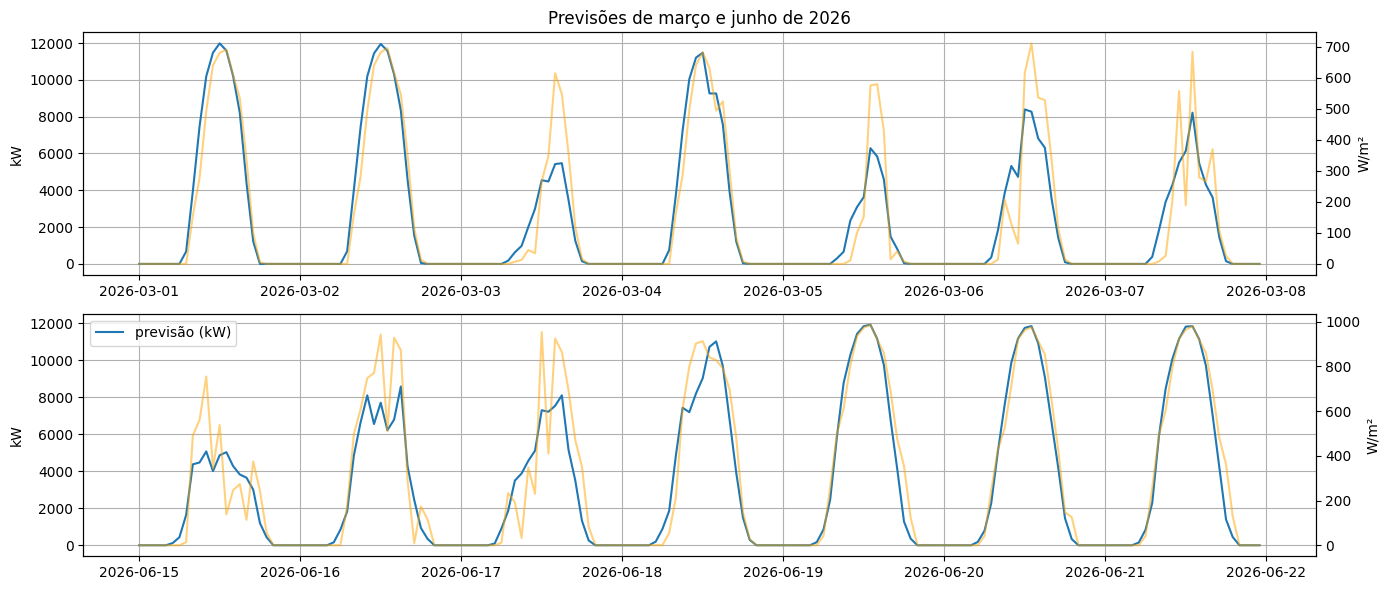

In [ ]:
# Verificação visual: previsões de alguns dias do teste
chk = test_X[['timestamp_utc']].assign(pred=pred_test.values, swflx_3=test_X['swflx_3'].values)
fig, ax = plt.subplots(2, 1, figsize=(14, 6))
w1 = chk[(chk['timestamp_utc'] >= '2026-03-01') & (chk['timestamp_utc'] < '2026-03-08')]
w2 = chk[(chk['timestamp_utc'] >= '2026-06-15') & (chk['timestamp_utc'] < '2026-06-22')]
for a, w_ in zip(ax, [w1, w2]):
    a.plot(w_['timestamp_utc'], w_['pred'], label='previsão (kW)')
    a2 = a.twinx(); a2.plot(w_['timestamp_utc'], w_['swflx_3'], 'orange', alpha=0.5, label='swflx_3'); a2.grid(False)
    a.set(ylabel='kW'); a2.set_ylabel('W/m²')
ax[0].set_title('Previsões de março e junho de 2026'); a.legend(loc='upper left')
plt.tight_layout()
print('Resumo da previsão: máximo', round(pred_test.max(), 1), '| média', round(pred_test.mean(), 1),
      '| zeros', int((pred_test == 0).sum()), 'de', len(pred_test))